# ML-Based Network Attack Detection on CIC-IoT-2023 — Phase 1
**University DevOps project · Phase 1: ML implementation, research-paper reproduction, two additional algorithms, evaluation, and novelty**

This notebook is the organised, end-to-end version of the original Colab notebook `230920_Devops (1) - Copy.ipynb` (kept unchanged as a backup). It:

1. loads the **existing** recovered CSV files (160K train / 40K test) — nothing is downloaded or regenerated;
2. audits the data (class balance, ordering bias, duplicates/leakage, a suspicious `IAT` feature);
3. re-runs and verifies the **existing Random Forest**;
4. reproduces the models of the selected paper (Neto *et al.*, *Sensors* 2023 — the CICIoT2023 paper);
5. adds two algorithms **not** used in the paper (HistGradientBoosting and k-Nearest Neighbours);
6. evaluates everything for **binary** (Benign vs Attack) and **8-class** (`attack_class`) detection;
7. implements and tests the novelty: a **confidence-gated, evidence-grounded, ATT&CK-referenced security recommendation engine**.

**How to run.** Locally: keep this notebook next to the `csv files/` folder. In Google Colab: upload the three CSV files (or the `csv files` folder) to `/content/` or to Google Drive, then *Runtime → Run all*. All libraries used (scikit-learn, pandas, numpy, scipy, matplotlib, joblib) are pre-installed in Colab. Full run time is roughly 15 minutes on an 8-core laptop; Colab's 2 vCPUs will be slower (the DNN is the slowest step).

> Scope note: frontend, backend, deployment, GitHub and Docker are deliberately **out of scope** for Phase 1.

## 1. Project Introduction
IoT networks contain many small devices (cameras, plugs, sensors) that are frequently attacked and often cannot protect themselves. A **network intrusion detection system (NIDS)** watches traffic and flags malicious flows. Machine learning can learn what attack traffic looks like from labelled examples.

**Goal of Phase 1**
* Build and fairly compare ML models that classify CIC-IoT-2023 traffic windows as **Benign vs Attack** (binary) and into **8 categories** (Benign, DDoS, DoS, Mirai, Recon, Spoofing, Web-based, BruteForce).
* Reproduce the algorithms of the selected research paper on our data and compare honestly.
* Add value beyond "attack / not attack": when an attack is detected, tell the analyst **what kind** of attack it most likely is, **why** (evidence), **how sure** the model is, and **which defensive actions** are relevant — while refusing to give category-specific advice when the model is unsure.

**Important distinction used throughout:** a *model prediction* is a statistical output; a *security recommendation* is advisory text mapped from that prediction for a human analyst. Nothing in this notebook blocks or prevents traffic.

## 2. Dataset Description
**Source.** CIC-IoT-2023 (Canadian Institute for Cybersecurity, University of New Brunswick) [1]: 33 attacks executed by malicious IoT devices against a 105-device smart-home topology, grouped into 7 categories plus Benign. Features are computed over fixed windows of 10 or 100 packets and averaged (paper §4), so each row is a *traffic window*, not a single packet.

**Our copy.** The original notebook loaded a Hugging Face repackaging of the dataset (`lacg030175/CIC-IoT-2023-neto-full`, configuration `random_3way`, 37.3M train / 4.67M validation / 4.67M test rows) [20] and saved:

| File | Rows | How it was created (original notebook) |
|---|---|---|
| `CIC_IoT_2023_train_160K.csv` | 160,000 | first 160,000 rows of the HF **train** split |
| `CIC_IoT_2023_test_40K.csv` | 40,000 | first 40,000 rows of the HF **test** split |
| `CIC_IoT_2023_200K.csv` | 200,000 | train + test concatenated |

**Columns (42):** 40 numeric traffic features + `attack_class` (8 categories) + `label` (0 = Benign, 1 = Attack). Compared with the paper's 46 features, six were not selected in the original notebook: `Number`, `Magnitue`, `Radius`, `Covariance`, `Variance`, `Weight`. The 34-class label (`Label_orig`) was also not kept, so the paper's 34-class experiment **cannot** be reproduced from these CSVs.

**Dataset-creation code (kept for provenance, intentionally *not* executed).** Re-running it would download ~1.6 GB and overwrite the preserved CSVs, which the project rules forbid. The essential lines from the original notebook were:
```python
dataset = load_dataset("lacg030175/CIC-IoT-2023-neto-full", "random_3way")
columns = features + ['attack_class', 'label']          # 40 features + 2 targets
train_df = dataset["train"].select_columns(columns).select(range(160000)).to_pandas()
test_df  = dataset["test"].select_columns(columns).select(range(40000)).to_pandas()
combined_df = pd.concat([train_df, test_df], ignore_index=True)
```
Earlier exploratory cells in the original notebook (random sampling attempts, cells that raised `NameError`, an unused 128K/32K re-split of the training file, and a Colab-only download cell) are not repeated here; they did not influence the saved CSVs or the reported Random Forest result.

In [1]:
%matplotlib inline
import os, json, time, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import joblib, scipy
from scipy import stats
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, matthews_corrcoef,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # LR/Perceptron/MLP may stop at max_iter; reported, not hidden
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 2))
SEED = 42
np.random.seed(SEED)

OUT = Path("phase1_outputs")
DIRS = {k: OUT / k for k in ("models", "figures", "results", "novelty")}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

# ---- chart style (validated reference palette; categorical slots used in fixed order) ----
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues_seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIVERGE = LinearSegmentedColormap.from_list("blue_red", ["#184f95", "#3987e5", "#f0efec", "#e34948", "#a12f2f"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.family": "sans-serif", "font.size": 9, "legend.frameon": False, "figure.dpi": 100,
})

def savefig(fig, name):
    path = DIRS["figures"] / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"[saved] {path}")

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)
print("Outputs folder:", OUT.resolve())

Python 3.12.6 | numpy 2.1.1 | pandas 2.2.3 | scikit-learn 1.6.0 | scipy 1.14.1 | matplotlib 3.9.2
Outputs folder: C:\Users\HP\Documents\Downloads\CIC_IoT_2023_recovered\phase1_outputs


## 3. Data Loading
The loader looks for the existing CSV files in the usual places (local `csv files/` folder, the notebook folder, Colab `/content`, or Google Drive). It never downloads or rewrites them.

In [2]:
TRAIN_FILE, TEST_FILE, COMBINED_FILE = "CIC_IoT_2023_train_160K.csv", "CIC_IoT_2023_test_40K.csv", "CIC_IoT_2023_200K.csv"
CANDIDATE_DIRS = [Path("csv files"), Path("."), Path("/content/csv files"), Path("/content"),
                  Path("/content/drive/MyDrive/CIC_IoT_2023_recovered/csv files"),
                  Path("/content/drive/MyDrive/CIC_IoT_2023_recovered")]
DATA_DIR = next((d for d in CANDIDATE_DIRS if (d / TRAIN_FILE).exists() and (d / TEST_FILE).exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find the recovered CSV files. Upload CIC_IoT_2023_train_160K.csv and "
        "CIC_IoT_2023_test_40K.csv (Colab: to /content or your Drive) and re-run this cell.")
print("Data folder:", DATA_DIR.resolve())

train_df = pd.read_csv(DATA_DIR / TRAIN_FILE)
test_df = pd.read_csv(DATA_DIR / TEST_FILE)
print("Training shape:", train_df.shape)
print("Testing shape :", test_df.shape)

if (DATA_DIR / COMBINED_FILE).exists():
    combined_df = pd.read_csv(DATA_DIR / COMBINED_FILE)
    print("Combined shape:", combined_df.shape,
          "| identical to train+test concatenation:", combined_df.equals(pd.concat([train_df, test_df], ignore_index=True)))
    del combined_df   # not needed further; the test set is always used separately

for name, d in (("train", train_df), ("test", test_df)):
    consistent = ((d["attack_class"] == "Benign") == (d["label"] == 0)).all()
    print(f"{name}: 'label' agrees with 'attack_class' (Benign <-> 0): {consistent}")

Data folder: C:\Users\HP\Documents\Downloads\CIC_IoT_2023_recovered\csv files
Training shape: (160000, 42)
Testing shape : (40000, 42)
Combined shape: (200000, 42) | identical to train+test concatenation: True
train: 'label' agrees with 'attack_class' (Benign <-> 0): True
test: 'label' agrees with 'attack_class' (Benign <-> 0): True


## 4. Exploratory Data Analysis
### 4.1 Class distribution and imbalance

              train_count  test_count  train_%  test_%
attack_class                                          
DDoS               116204       29152   72.628  72.880
DoS                 27887        6877   17.429  17.192
Mirai                9101        2263    5.688   5.658
Benign               3860         939    2.412   2.348
Spoofing             1671         447    1.044   1.118
Recon                1167         292    0.729   0.730
Web-based              55          18    0.034   0.045
BruteForce             55          12    0.034   0.030

Binary label (train): {1: 156140, 0: 3860} | (test): {1: 39061, 0: 939}
Imbalance ratio DDoS : BruteForce in train = 2113 : 1
A model that always answers 'Attack' would already score accuracy 0.9765 on the test set.
[saved] phase1_outputs\figures\eda_class_distribution.png


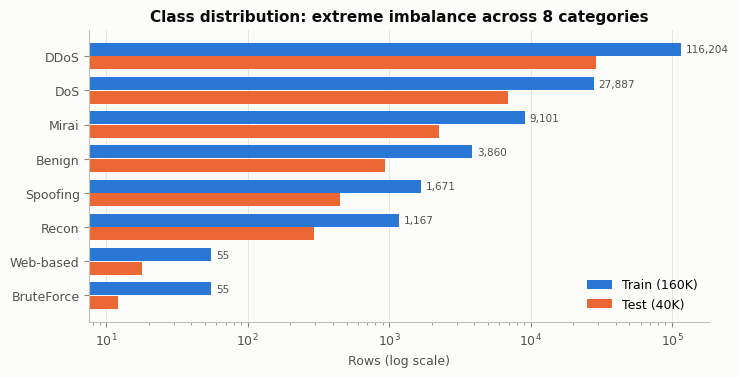

In [3]:
dist = pd.DataFrame({"train_count": train_df["attack_class"].value_counts(),
                     "test_count": test_df["attack_class"].value_counts()})
dist["train_%"] = (dist["train_count"] / len(train_df) * 100).round(3)
dist["test_%"] = (dist["test_count"] / len(test_df) * 100).round(3)
dist = dist.sort_values("train_count", ascending=False)
print(dist.to_string())
print("\nBinary label (train):", train_df["label"].value_counts().to_dict(), "| (test):", test_df["label"].value_counts().to_dict())
print(f"Imbalance ratio DDoS : BruteForce in train = {dist.loc['DDoS','train_count'] / dist.loc['BruteForce','train_count']:.0f} : 1")
print(f"A model that always answers 'Attack' would already score accuracy {test_df['label'].mean():.4f} on the test set.")
dist.to_csv(DIRS["results"] / "class_distribution.csv")

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(dist)); h = 0.38
ax.barh(y - h/2 - 0.01, dist["train_count"], height=h, color=SERIES[0], label="Train (160K)")
ax.barh(y + h/2 + 0.01, dist["test_count"], height=h, color=SERIES[1], label="Test (40K)")
ax.set_yticks(y, dist.index); ax.invert_yaxis(); ax.set_xscale("log")
ax.set_xlabel("Rows (log scale)"); ax.set_title("Class distribution: extreme imbalance across 8 categories")
for yi, (a, b) in enumerate(zip(dist["train_count"], dist["test_count"])):
    ax.text(a * 1.08, yi - h/2, f"{a:,}", va="center", fontsize=7.5, color=INK2)
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
savefig(fig, "eda_class_distribution"); plt.show()

### 4.2 Data quality: missing values, infinities, constant and duplicate features

In [4]:
FEATURES = [c for c in train_df.columns if c not in ("attack_class", "label")]
print("Number of features:", len(FEATURES))
for name, d in (("train", train_df), ("test", test_df)):
    X = d[FEATURES].to_numpy()
    print(f"{name}: NaN = {int(np.isnan(X).sum())}, +/-inf = {int(np.isinf(X).sum())}")
constant = [c for c in FEATURES if train_df[c].nunique() <= 1]
print("Constant (zero-variance) features in train:", constant)
identical_pairs = [(a, b) for i, a in enumerate(FEATURES) for b in FEATURES[i+1:] if train_df[a].equals(train_df[b])]
print("Feature pairs with identical values in train:", identical_pairs)
print("\nThese features are kept so the feature set matches the original notebook; they carry no extra "
      "information but do not harm the models (tree models ignore them; StandardScaler leaves zero-variance columns at 0).")
print("\nSummary statistics (train):")
print(train_df[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].to_string(float_format=lambda v: f"{v:,.4g}"))

Number of features: 40
train: NaN = 0, +/-inf = 0
test: NaN = 0, +/-inf = 0
Constant (zero-variance) features in train: ['ece_flag_number', 'cwr_flag_number', 'Telnet', 'SMTP', 'IRC', 'DHCP']
Feature pairs with identical values in train: [('Rate', 'Srate'), ('ece_flag_number', 'cwr_flag_number'), ('ece_flag_number', 'Telnet'), ('ece_flag_number', 'SMTP'), ('ece_flag_number', 'IRC'), ('ece_flag_number', 'DHCP'), ('cwr_flag_number', 'Telnet'), ('cwr_flag_number', 'SMTP'), ('cwr_flag_number', 'IRC'), ('cwr_flag_number', 'DHCP'), ('Telnet', 'SMTP'), ('Telnet', 'IRC'), ('Telnet', 'DHCP'), ('SMTP', 'IRC'), ('SMTP', 'DHCP'), ('IRC', 'DHCP'), ('IPv', 'LLC')]

These features are kept so the feature set matches the original notebook; they carry no extra information but do not harm the models (tree models ignore them; StandardScaler leaves zero-variance columns at 0).

Summary statistics (train):
                     mean       std       min       50%       max
flow_duration       5.734     270.7

### 4.3 Did taking the *first* 160K / 40K rows introduce ordering bias?
If the source split were sorted (for example by attack type or capture time), the first rows would not be representative. Three checks:
1. **Class mix vs. the full HF train split** (37,349,263 rows; counts printed by the original notebook, cell 2).
2. **Adjacency test:** in a shuffled file, the probability that two consecutive rows share a class is Σp². Clustering (sorted data) would push it higher.
3. **Drift across the file:** the benign share in each quarter of the file.

In [5]:
FULL_HF_TRAIN_COUNTS = {"DDoS": 27188516, "DoS": 6471500, "Mirai": 2107302, "Benign": 878556,
                        "Spoofing": 389321, "Recon": 283767, "Web-based": 19907, "BruteForce": 10394}
tot = sum(FULL_HF_TRAIN_COUNTS.values())
obs = train_df["attack_class"].value_counts().reindex(FULL_HF_TRAIN_COUNTS.keys())
exp = np.array([FULL_HF_TRAIN_COUNTS[k] / tot * len(train_df) for k in obs.index])
chi = stats.chisquare(obs.values, exp)
order_tbl = pd.DataFrame({"first_160K_%": (obs / len(train_df) * 100).round(4),
                          "full_HF_train_%": pd.Series({k: v / tot * 100 for k, v in FULL_HF_TRAIN_COUNTS.items()}).round(4),
                          "observed": obs.values, "expected_if_random": exp.round(1)})
print(order_tbl.to_string())
print(f"\nChi-square goodness of fit: statistic = {chi.statistic:.2f}, p = {chi.pvalue:.4f}")

for name, d in (("train", train_df), ("test", test_df)):
    a = d["attack_class"].to_numpy()
    p = d["attack_class"].value_counts(normalize=True).to_numpy()
    quarters = np.array_split(np.arange(len(d)), 4)
    print(f"{name}: consecutive-same-class rate = {(a[1:] == a[:-1]).mean():.4f} "
          f"(expected if shuffled = {(p**2).sum():.4f}); benign % per quarter = "
          f"{[round(float((d['label'].to_numpy()[q] == 0).mean() * 100), 2) for q in quarters]}")

            first_160K_%  full_HF_train_%  observed  expected_if_random
DDoS             72.6275          72.7953    116204            116472.5
DoS              17.4294          17.3270     27887             27723.2
Mirai             5.6881           5.6422      9101              9027.4
Benign            2.4125           2.3523      3860              3763.6
Spoofing          1.0444           1.0424      1671              1667.8
Recon             0.7294           0.7598      1167              1215.6
Web-based         0.0344           0.0533        55                85.3
BruteForce        0.0344           0.0278        55                44.5

Chi-square goodness of fit: statistic = 19.82, p = 0.0060
train: consecutive-same-class rate = 0.5620 (expected if shuffled = 0.5618); benign % per quarter = [2.45, 2.4, 2.46, 2.33]
test: consecutive-same-class rate = 0.5640 (expected if shuffled = 0.5646); benign % per quarter = [2.26, 2.12, 2.52, 2.49]


**Interpretation.** Consecutive rows are no more alike than random order predicts, and the benign share is stable across the file, so the source split was already shuffled and "first N rows" behaves like a random sample. Every class proportion is within 0.2 percentage points of the full split. The chi-square test is nevertheless significant, driven mainly by the rarest class: **Web-based** has 55 training rows where ≈85 would be expected. This slightly under-represents an already tiny class. Fixing it would require re-sampling from the full 37M-row dataset, which is outside the rules of this phase, so the split is kept and the limitation is reported.

### 4.4 Duplicates and train/test leakage

In [6]:
train_hash = pd.util.hash_pandas_object(train_df[FEATURES], index=False)
test_hash = pd.util.hash_pandas_object(test_df[FEATURES], index=False)
print("Duplicate feature vectors inside train:", int(train_hash.duplicated().sum()))
print("Duplicate feature vectors inside test :", int(test_hash.duplicated().sum()))
TEST_SEEN_IN_TRAIN = test_hash.isin(set(train_hash)).to_numpy()
print(f"Test rows whose exact feature vector also appears in train: {TEST_SEEN_IN_TRAIN.sum():,} "
      f"({TEST_SEEN_IN_TRAIN.mean()*100:.2f}%)")
print("  by class:", test_df.loc[TEST_SEEN_IN_TRAIN, "attack_class"].value_counts().to_dict())
conflicts = train_df.assign(h=train_hash).groupby("h")["attack_class"].nunique()
print("Identical feature vectors carrying different labels in train:", int((conflicts > 1).sum()))

Duplicate feature vectors inside train: 4461
Duplicate feature vectors inside test : 404
Test rows whose exact feature vector also appears in train: 1,986 (4.96%)
  by class: {'DDoS': 1871, 'DoS': 83, 'Mirai': 32}
Identical feature vectors carrying different labels in train: 0


**Interpretation.** About 5% of test rows are exact copies of training rows — all flood traffic (DDoS/DoS/Mirai), where many 100-packet windows are genuinely identical. This is mild, *natural* overlap rather than a coding error, but it can inflate scores. Section 11 therefore also reports every model on the **de-duplicated** test subset. No identical vector has conflicting labels.

### 4.5 A suspicious feature: `IAT`
The paper defines `IAT` as "the time difference with the previous packet", yet its values are around 83 million for most rows (paper Table 5 shows the same). Below we inspect it **using training data only**.

               count         10%         50%         90%
attack_class                                            
Benign         3,860  0.00131971    0.051977 1.66524e+08
BruteForce        55  0.00518319   0.0263319 1.66601e+08
DDoS         116,204 8.30759e+07 8.31289e+07 8.33619e+07
DoS           27,887 8.29464e+07 8.29853e+07 8.30164e+07
Mirai          9,101  8.3586e+07 8.36938e+07 8.37849e+07
Recon          1,167  0.00133036 8.32422e+07 1.66847e+08
Spoofing       1,671  0.00020299 1.66604e+08 1.66861e+08
Web-based         55  0.00166369 1.66482e+08 1.67639e+08

One-line rule 'IAT > 1000 => Attack' on TRAIN: accuracy = 0.9789, macro-F1 = 0.7617
[saved] phase1_outputs\figures\eda_iat_by_class.png


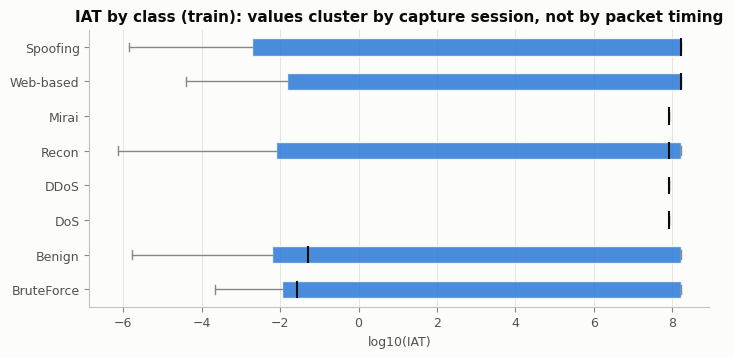

In [7]:
iat_tbl = train_df.groupby("attack_class")["IAT"].describe(percentiles=[0.1, 0.5, 0.9])[["count", "10%", "50%", "90%"]]
print(iat_tbl.to_string(float_format=lambda v: f"{v:,.6g}"))

thr_rule = (train_df["IAT"] > 1000).astype(int)
print(f"\nOne-line rule 'IAT > 1000 => Attack' on TRAIN: accuracy = {accuracy_score(train_df['label'], thr_rule):.4f}, "
      f"macro-F1 = {f1_score(train_df['label'], thr_rule, average='macro'):.4f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
order = iat_tbl.sort_values("50%").index.tolist()
data = [np.log10(train_df.loc[train_df["attack_class"] == c, "IAT"].to_numpy() + 1e-9) for c in order]
bp = ax.boxplot(data, vert=False, tick_labels=order, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, linewidth=1.5), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for b in bp["boxes"]:
    b.set(facecolor=SERIES[0], alpha=0.85, edgecolor=SURFACE)
ax.set_xlabel("log10(IAT)"); ax.set_title("IAT by class (train): values cluster by capture session, not by packet timing")
ax.grid(axis="y", visible=False)
savefig(fig, "eda_iat_by_class"); plt.show()

**Interpretation.** `IAT` medians differ by class in a way that does not look like real inter-arrival times: most Benign and BruteForce windows have small values, while DDoS ≈ 8.31×10⁷, DoS ≈ 8.30×10⁷, Mirai ≈ 8.37×10⁷, and Spoofing/Web ≈ 1.67×10⁸. That pattern matches a **capture-session / timestamp artefact**: rows recorded in the same capture share similar values. A model can use it as a shortcut that would not exist on a new network. We keep `IAT` in the main experiments (it is part of the published feature set and of the original notebook), but Section 11 measures how much each model depends on it (**IAT ablation**).

### 4.6 Feature correlations

[saved] phase1_outputs\figures\eda_feature_correlation.png


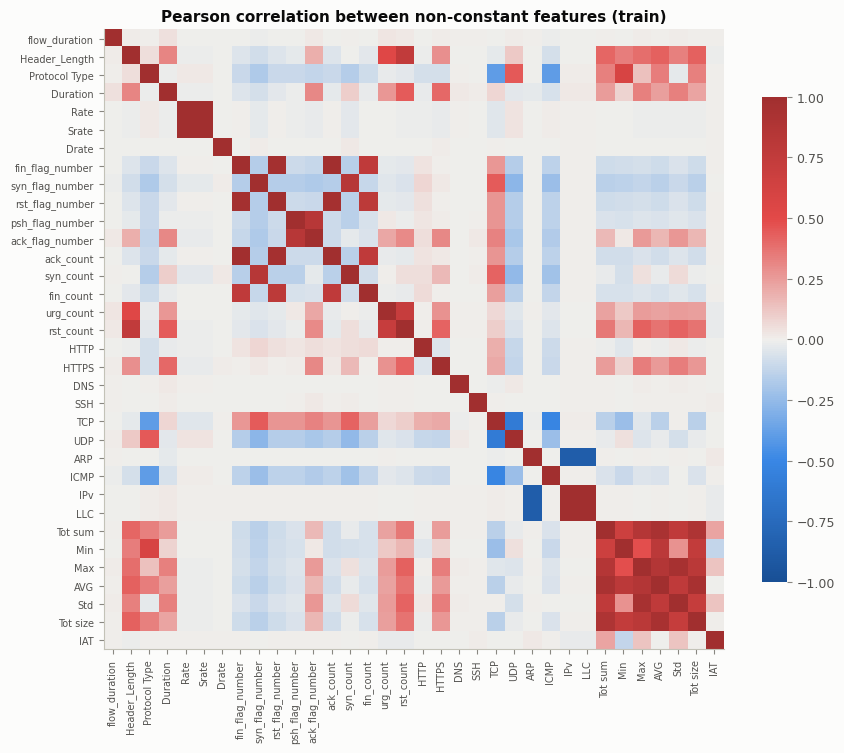

Feature pairs with |r| > 0.95: [('Rate', 'Srate', np.float64(1.0)), ('fin_flag_number', 'rst_flag_number', np.float64(0.976)), ('fin_flag_number', 'ack_count', np.float64(0.986)), ('rst_flag_number', 'ack_count', np.float64(0.963)), ('IPv', 'LLC', np.float64(1.0)), ('Max', 'Std', np.float64(0.953))]


In [8]:
nonconst = [c for c in FEATURES if c not in constant]
corr = train_df[nonconst].corr()
fig, ax = plt.subplots(figsize=(10, 8.4))
im = ax.imshow(corr.values, cmap=DIVERGE, vmin=-1, vmax=1)
ax.set_xticks(range(len(nonconst)), nonconst, rotation=90, fontsize=7)
ax.set_yticks(range(len(nonconst)), nonconst, fontsize=7)
ax.grid(False); ax.set_title("Pearson correlation between non-constant features (train)")
cb = fig.colorbar(im, ax=ax, shrink=0.75); cb.outline.set_visible(False)
savefig(fig, "eda_feature_correlation"); plt.show()
high = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(nonconst) for b in nonconst[i+1:] if abs(corr.loc[a, b]) > 0.95]
print("Feature pairs with |r| > 0.95:", high)

## 5. Data Preprocessing
Decisions (and why):

| Step | Choice | Reason |
|---|---|---|
| Features | all 40 numeric features | identical to the original notebook; the paper also used all extracted features |
| Missing / infinite values | replace ±inf with NaN, fill with **training** medians | kept from the original notebook (the files currently contain none, but this protects future data) |
| Targets | `label` (binary) and `attack_class` (8 classes, integer-encoded) | both tasks are supported by the CSVs |
| Scaling | `StandardScaler` **inside** each model pipeline, fitted on training data only | follows the paper; tree models do not need it |
| Model selection | a stratified **20% validation split carved out of the training file** | the test set is never used for tuning, thresholds, or model choice |
| Test set | the untouched 40K file | final evaluation only |

The original notebook also contained an unused 128K/32K re-split of the training file; it is not needed because a separate test file exists.

In [9]:
# --- original notebook preprocessing (unchanged) ---
X_train = train_df.drop(columns=["attack_class", "label"])
y_train = train_df["label"]
X_test = test_df.drop(columns=["attack_class", "label"])
y_test = test_df["label"]
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# --- multiclass target ---
le = LabelEncoder().fit(train_df["attack_class"])
CLASS_NAMES = list(le.classes_)
y_train_mc = le.transform(train_df["attack_class"])
y_test_mc = le.transform(test_df["attack_class"])
BENIGN_ID = CLASS_NAMES.index("Benign")

# --- validation split used ONLY for model selection / thresholds ---
idx_sub, idx_val = train_test_split(np.arange(len(X_train)), test_size=0.20,
                                    stratify=train_df["attack_class"], random_state=SEED)
X_sub, X_val = X_train.iloc[idx_sub], X_train.iloc[idx_val]
y_sub_bin, y_val_bin = y_train.to_numpy()[idx_sub], y_train.to_numpy()[idx_val]
y_sub_mc, y_val_mc = y_train_mc[idx_sub], y_train_mc[idx_val]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Classes (encoded order):", dict(enumerate(CLASS_NAMES)))
print("Model-selection split: sub-train", X_sub.shape, "| validation", X_val.shape)
print("Validation class counts:", dict(zip(CLASS_NAMES, np.bincount(y_val_mc))))
joblib.dump({"features": FEATURES, "train_medians": train_medians, "class_names": CLASS_NAMES,
             "label_encoder": le}, DIRS["models"] / "preprocessing.joblib")
print("[saved] preprocessing artefacts -> phase1_outputs/models/preprocessing.joblib")

X_train: (160000, 40) | X_test: (40000, 40)
Classes (encoded order): {0: 'Benign', 1: 'BruteForce', 2: 'DDoS', 3: 'DoS', 4: 'Mirai', 5: 'Recon', 6: 'Spoofing', 7: 'Web-based'}
Model-selection split: sub-train (128000, 40) | validation (32000, 40)
Validation class counts: {'Benign': np.int64(772), 'BruteForce': np.int64(11), 'DDoS': np.int64(23241), 'DoS': np.int64(5578), 'Mirai': np.int64(1820), 'Recon': np.int64(233), 'Spoofing': np.int64(334), 'Web-based': np.int64(11)}
[saved] preprocessing artefacts -> phase1_outputs/models/preprocessing.joblib


### 5.1 Evaluation utilities
Every model is scored with the same function on the same test set. For **binary** detection, *precision / recall / F1* refer to the **Attack** class (as in the original notebook); because Attack is 97.7% of the data these look high for almost any model, so we also report **Benign-class** metrics, **macro-F1** (both classes weighted equally), **weighted-F1**, **balanced accuracy**, and the **Matthews correlation coefficient (MCC)**. For **multiclass**, precision / recall / F1 are **macro-averaged** (every class counts equally, which is what exposes weak minority classes).

In [10]:
RESULTS = {"binary": {}, "multiclass": {}}
PREDS = {"binary": {}, "multiclass": {}}
MODELS = {"binary": {}, "multiclass": {}}
BIN_NAMES = ["Benign (0)", "Attack (1)"]

def compute_metrics(task, y_true, y_pred):
    m = {"accuracy": accuracy_score(y_true, y_pred)}
    if task == "binary":
        m["precision"] = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
        m["recall"] = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
        m["f1"] = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
        m["benign_precision"] = precision_score(y_true, y_pred, pos_label=0, zero_division=0)
        m["benign_recall"] = recall_score(y_true, y_pred, pos_label=0, zero_division=0)
        m["benign_f1"] = f1_score(y_true, y_pred, pos_label=0, zero_division=0)
    else:
        m["precision"] = precision_score(y_true, y_pred, average="macro", zero_division=0)
        m["recall"] = recall_score(y_true, y_pred, average="macro", zero_division=0)
        m["f1"] = f1_score(y_true, y_pred, average="macro", zero_division=0)
    m["macro_precision"] = precision_score(y_true, y_pred, average="macro", zero_division=0)
    m["macro_recall"] = recall_score(y_true, y_pred, average="macro", zero_division=0)
    m["macro_f1"] = f1_score(y_true, y_pred, average="macro", zero_division=0)
    m["weighted_f1"] = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    m["balanced_accuracy"] = balanced_accuracy_score(y_true, y_pred)
    m["mcc"] = matthews_corrcoef(y_true, y_pred)
    return m

def evaluate(name, task, model, X_eval, y_true, train_time, source, verbose=True):
    """Predict once, time it, compute all metrics, store results, print the report."""
    t0 = time.perf_counter()
    y_pred = np.asarray(model.predict(X_eval))
    pred_time = time.perf_counter() - t0
    m = compute_metrics(task, y_true, y_pred)
    m.update(model=name, task=task, source=source, train_time_s=train_time,
             predict_time_s=pred_time, predict_us_per_flow=pred_time / len(X_eval) * 1e6)
    RESULTS[task][name] = m; PREDS[task][name] = y_pred; MODELS[task][name] = model
    if verbose:
        names = BIN_NAMES if task == "binary" else CLASS_NAMES
        print(f"===== {name} | {task} =====")
        print(f"Accuracy {m['accuracy']:.4f} | Precision {m['precision']:.4f} | Recall {m['recall']:.4f} | F1 {m['f1']:.4f}"
              + ("  (Attack class)" if task == "binary" else "  (macro)"))
        print(f"Macro-F1 {m['macro_f1']:.4f} | Weighted-F1 {m['weighted_f1']:.4f} | Balanced acc {m['balanced_accuracy']:.4f} | MCC {m['mcc']:.4f}")
        print(f"Train time {train_time:.2f} s | Predict time {pred_time:.3f} s ({m['predict_us_per_flow']:.2f} us/flow)")
        print(classification_report(y_true, y_pred, labels=range(len(names)), target_names=names, digits=4, zero_division=0))
        print("Confusion matrix (rows = true, cols = predicted):")
        print(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=range(len(names))), index=names, columns=names).to_string())
        print()
    return y_pred

def timed_fit(model, X, y):
    t0 = time.perf_counter(); model.fit(X, y); return model, time.perf_counter() - t0

print("Evaluation utilities ready.")

Evaluation utilities ready.


## 6. Existing Random Forest Implementation
The two cells below are the **original notebook's code, unchanged** (model + evaluation). We re-run them to verify the previously reported numbers, then add the extra metrics.

In [11]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")
_t0 = time.perf_counter()
model.fit(X_train, y_train)
rf_train_time = time.perf_counter() - _t0
print("Training completed.", f"({rf_train_time:.1f} s)")

Training Random Forest...
Training completed. (7.3 s)


In [12]:
# Original evaluation cell (unchanged)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
print("========== MODEL RESULTS ==========")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")
print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_test, y_pred, zero_division=0))
print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(y_test, y_pred))

# ---- verification against the results recorded in the original notebook ----
RECORDED = {"accuracy": 0.9963, "precision": 0.9980, "recall": 0.9982, "f1": 0.9981, "cm": [[861, 78], [69, 38992]]}
now = {"accuracy": round(accuracy, 4), "precision": round(precision, 4), "recall": round(recall, 4), "f1": round(f1, 4),
       "cm": confusion_matrix(y_test, y_pred).tolist()}
print("\nVerification vs original notebook:", "EXACT MATCH" if now == RECORDED else f"DIFFERENT -> {now}")

========== MODEL RESULTS ==========
Accuracy : 0.9963
Precision: 0.9980
Recall   : 0.9982
F1-Score : 0.9981

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.93      0.92      0.92       939
           1       1.00      1.00      1.00     39061

    accuracy                           1.00     40000
   macro avg       0.96      0.96      0.96     40000
weighted avg       1.00      1.00      1.00     40000


========== CONFUSION MATRIX ==========
[[  861    78]
 [   69 38992]]

Verification vs original notebook: EXACT MATCH


In [13]:
# Same model, full metric set + a majority-class baseline for context
evaluate("Random Forest", "binary", model, X_test, y_test.to_numpy(), rf_train_time, source="existing notebook / paper")
dummy_bin, t = timed_fit(DummyClassifier(strategy="most_frequent"), X_train, y_train)
evaluate("Majority baseline", "binary", dummy_bin, X_test, y_test.to_numpy(), t, source="reference", verbose=False)
dummy_mc, t = timed_fit(DummyClassifier(strategy="most_frequent"), X_train, y_train_mc)
evaluate("Majority baseline", "multiclass", dummy_mc, X_test, y_test_mc, t, source="reference", verbose=False)
b = RESULTS["binary"]["Majority baseline"]
print(f"Majority baseline (always 'Attack'): accuracy {b['accuracy']:.4f}, Attack-F1 {b['f1']:.4f}, macro-F1 {b['macro_f1']:.4f}, balanced acc {b['balanced_accuracy']:.4f}")

===== Random Forest | binary =====
Accuracy 0.9963 | Precision 0.9980 | Recall 0.9982 | F1 0.9981  (Attack class)
Macro-F1 0.9597 | Weighted-F1 0.9963 | Balanced acc 0.9576 | MCC 0.9195
Train time 7.35 s | Predict time 0.141 s (3.53 us/flow)
              precision    recall  f1-score   support

  Benign (0)     0.9258    0.9169    0.9213       939
  Attack (1)     0.9980    0.9982    0.9981     39061

    accuracy                         0.9963     40000
   macro avg     0.9619    0.9576    0.9597     40000
weighted avg     0.9963    0.9963    0.9963     40000

Confusion matrix (rows = true, cols = predicted):
            Benign (0)  Attack (1)
Benign (0)         861          78
Attack (1)          69       38992

Majority baseline (always 'Attack'): accuracy 0.9765, Attack-F1 0.9881, macro-F1 0.4941, balanced acc 0.5000


**Reading the existing result correctly.** The recorded numbers reproduce exactly. However, *Precision 0.998 / Recall 0.998 / F1 0.998* describe the **Attack** class, and a model that always says "Attack" already reaches accuracy 0.977 and Attack-F1 0.988. The informative numbers are the **Benign** row (precision ≈ 0.93, recall ≈ 0.92), **macro-F1 ≈ 0.96** and balanced accuracy: 78 of 939 benign windows (8.3%) are raised as false alarms and 69 attacks are missed.

## 7. Research Paper Model Reproduction
**Paper:** E. C. P. Neto *et al.*, "CICIoT2023: A Real-Time Dataset and Benchmark for Large-Scale Attacks in IoT Environment," *Sensors* 23(13):5941, 2023 [1].

**What the paper does (Section 5):**
* **Algorithms (exactly five):** Logistic Regression, Perceptron, AdaBoost, Random Forest, Deep Neural Network.
* **Data:** all CSV files merged and shuffled (PySpark); timestamp removed; all other 46 features used. No feature selection.
* **Split / preprocessing:** 80% train / 20% test, **StandardScaler**.
* **Tasks:** binary (benign vs malicious), 8 classes (benign + 7 categories), 34 classes (benign + 33 attacks).
* **Metrics:** accuracy, recall, precision, F1. The paper does not state the averaging, but its 8-class RF has accuracy 0.994 with F1 0.719, which is only possible with **macro** averaging; we therefore compare macro-averaged metrics.
* **Hyper-parameters:** not reported (nor the DNN architecture). We use scikit-learn defaults; the DNN is a scikit-learn `MLPClassifier` with two hidden layers (128, 64), ReLU, Adam, and early stopping.

**Differences between the paper and our reproduction**

| Aspect | Paper | This notebook |
|---|---|---|
| Rows | ≈46.7M (all data), 80/20 split | 160K train / 40K test (separate HF splits) |
| Features | 46 | 40 (6 not selected originally) |
| Tasks | binary, 8-class, 34-class | binary, 8-class (34-class impossible: fine labels not in CSVs) |
| DNN | unspecified architecture/framework | scikit-learn MLP (128, 64) |
| Hyper-parameters | unreported | scikit-learn defaults (LR `max_iter=1000`) |
| Random Forest | default-style RF | the existing RF (100 trees). Feature scaling does not change tree splits' ordering, so the paper's "scale then RF" and our unscaled RF are equivalent in practice |

Because the data volume, feature set and test split differ, matching numbers would not *prove* equivalence; we compare trends and magnitudes.

In [14]:
PAPER_TABLE6 = pd.DataFrame({
    ("binary", "Logistic Regression"): [0.989023188, 0.890400624, 0.863157959, 0.876258983],
    ("binary", "Perceptron"):          [0.9817525, 0.7970288, 0.825432, 0.8105374],
    ("binary", "AdaBoost"):            [0.995899, 0.947303, 0.965631, 0.956273],
    ("binary", "Random Forest"):       [0.99680798, 0.965163906, 0.965395244, 0.965279544],
    ("binary", "DNN (MLP)"):           [0.994422814, 0.933277496, 0.947579486, 0.940305998],
    ("multiclass", "Logistic Regression"): [0.831674188, 0.696055597, 0.512409686, 0.539424048],
    ("multiclass", "Perceptron"):          [0.8663152, 0.6591315, 0.5239188, 0.5551339],
    ("multiclass", "AdaBoost"):            [0.351357, 0.487789, 0.464924, 0.368663],
    ("multiclass", "Random Forest"):       [0.994368173, 0.91001105, 0.705407564, 0.71928904],
    ("multiclass", "DNN (MLP)"):           [0.991147043, 0.906642708, 0.679434746, 0.69726491],
}, index=["accuracy", "recall", "precision", "f1"]).T
print("Paper Table 6 (binary = '2 classes', multiclass = '8 classes'):")
print(PAPER_TABLE6.round(4).to_string())

def make_paper_models():
    return {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
        "Perceptron": make_pipeline(StandardScaler(), Perceptron(random_state=SEED)),
        "AdaBoost": make_pipeline(StandardScaler(), AdaBoostClassifier(random_state=SEED)),
        "DNN (MLP)": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True,
                                                                   max_iter=200, random_state=SEED)),
    }

Paper Table 6 (binary = '2 classes', multiclass = '8 classes'):
                                accuracy  recall  precision      f1
binary     Logistic Regression    0.9890  0.8904     0.8632  0.8763
           Perceptron             0.9818  0.7970     0.8254  0.8105
           AdaBoost               0.9959  0.9473     0.9656  0.9563
           Random Forest          0.9968  0.9652     0.9654  0.9653
           DNN (MLP)              0.9944  0.9333     0.9476  0.9403
multiclass Logistic Regression    0.8317  0.6961     0.5124  0.5394
           Perceptron             0.8663  0.6591     0.5239  0.5551
           AdaBoost               0.3514  0.4878     0.4649  0.3687
           Random Forest          0.9944  0.9100     0.7054  0.7193
           DNN (MLP)              0.9911  0.9066     0.6794  0.6973


### 7.1 Binary classification (Benign vs Attack)
The Random Forest result is the one from Section 6 (same algorithm and settings).

In [15]:
for name, m in make_paper_models().items():
    m, t = timed_fit(m, X_train, y_train.to_numpy())
    evaluate(name, "binary", m, X_test, y_test.to_numpy(), t, source="paper")

===== Logistic Regression | binary =====
Accuracy 0.9889 | Precision 0.9928 | Recall 0.9958 | F1 0.9943  (Attack class)
Macro-F1 0.8703 | Weighted-F1 0.9885 | Balanced acc 0.8472 | MCC 0.7424
Train time 2.01 s | Predict time 0.029 s (0.72 us/flow)
              precision    recall  f1-score   support

  Benign (0)     0.8010    0.6986    0.7463       939
  Attack (1)     0.9928    0.9958    0.9943     39061

    accuracy                         0.9889     40000
   macro avg     0.8969    0.8472    0.8703     40000
weighted avg     0.9883    0.9889    0.9885     40000

Confusion matrix (rows = true, cols = predicted):
            Benign (0)  Attack (1)
Benign (0)         656         283
Attack (1)         163       38898

===== Perceptron | binary =====
Accuracy 0.9827 | Precision 0.9842 | Recall 0.9983 | F1 0.9912  (Attack class)
Macro-F1 0.7327 | Weighted-F1 0.9790 | Balanced acc 0.6658 | MCC 0.5169
Train time 0.60 s | Predict time 0.024 s (0.60 us/flow)
              precision    rec

### 7.2 Multiclass classification (8 categories)
Labels are integer-encoded for all models (scikit-learn's MLP with early stopping fails on text labels, a known library issue).

In [16]:
rf_mc, t = timed_fit(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train, y_train_mc)
evaluate("Random Forest", "multiclass", rf_mc, X_test, y_test_mc, t, source="existing notebook / paper")
for name, m in make_paper_models().items():
    m, t = timed_fit(m, X_train, y_train_mc)
    evaluate(name, "multiclass", m, X_test, y_test_mc, t, source="paper")

===== Random Forest | multiclass =====
Accuracy 0.9946 | Precision 0.8279 | Recall 0.7058 | F1 0.7177  (macro)
Macro-F1 0.7177 | Weighted-F1 0.9942 | Balanced acc 0.7058 | MCC 0.9876
Train time 9.10 s | Predict time 0.243 s (6.07 us/flow)
              precision    recall  f1-score   support

      Benign     0.8805    0.9734    0.9246       939
  BruteForce     1.0000    0.0833    0.1538        12
        DDoS     0.9998    0.9998    0.9998     29152
         DoS     0.9999    0.9997    0.9998      6877
       Mirai     0.9996    0.9973    0.9985      2263
       Recon     0.8539    0.7808    0.8157       292
    Spoofing     0.8897    0.8121    0.8491       447
   Web-based     0.0000    0.0000    0.0000        18

    accuracy                         0.9946     40000
   macro avg     0.8279    0.7058    0.7177     40000
weighted avg     0.9942    0.9946    0.9942     40000

Confusion matrix (rows = true, cols = predicted):
            Benign  BruteForce   DDoS   DoS  Mirai  Recon  S

### 7.3 Our reproduction vs. the paper (macro-averaged)

In [17]:
rows = []
for (task, name), p in PAPER_TABLE6.iterrows():
    r = RESULTS[task][name]
    rows.append({"task": task, "model": name,
                 "paper_acc": p["accuracy"], "ours_acc": r["accuracy"],
                 "paper_macroF1": p["f1"], "ours_macroF1": r["macro_f1"],
                 "paper_macroRecall": p["recall"], "ours_macroRecall": r["macro_recall"],
                 "paper_macroPrec": p["precision"], "ours_macroPrec": r["macro_precision"],
                 "delta_macroF1": r["macro_f1"] - p["f1"]})
repro = pd.DataFrame(rows)
print(repro.round(4).to_string(index=False))
repro.to_csv(DIRS["results"] / "paper_reproduction_comparison.csv", index=False)
for task in ("binary", "multiclass"):
    sub = repro[repro.task == task]
    rank_paper = sub.sort_values("paper_macroF1", ascending=False).model.tolist()
    rank_ours = sub.sort_values("ours_macroF1", ascending=False).model.tolist()
    print(f"\n{task}: paper ranking by F1 = {rank_paper}\n{' ' * len(task)}  our ranking by F1   = {rank_ours}")

      task               model  paper_acc  ours_acc  paper_macroF1  ours_macroF1  paper_macroRecall  ours_macroRecall  paper_macroPrec  ours_macroPrec  delta_macroF1
    binary Logistic Regression     0.9890    0.9888         0.8763        0.8703             0.8904            0.8472           0.8632          0.8969        -0.0060
    binary          Perceptron     0.9818    0.9826         0.8105        0.7327             0.7970            0.6658           0.8254          0.9029        -0.0778
    binary            AdaBoost     0.9959    0.9945         0.9563        0.9418             0.9473            0.9572           0.9656          0.9274        -0.0145
    binary       Random Forest     0.9968    0.9963         0.9653        0.9597             0.9652            0.9576           0.9654          0.9619        -0.0055
    binary           DNN (MLP)     0.9944    0.9930         0.9403        0.9244             0.9333            0.9314           0.9476          0.9176        -0.0159
mult

## 8. Additional Model 1 — Histogram-based Gradient Boosting (HGB)
**Not in the paper.** The paper's boosting method is AdaBoost (re-weights samples and adds depth-1 "stumps"). HGB is a different algorithm: *gradient* boosting [3] that fits each new, deeper tree to the gradient of the log-loss, on features bucketed into 255 histogram bins — the LightGBM approach [4], implemented in scikit-learn [6].

**Why it suits CIC-IoT-2023:** tabular, heavy-tailed features (rates, sizes, counts) need no scaling for trees; histogram binning makes training on 160K rows take seconds; native `class_weight` handles the 2,100:1 imbalance; it outputs probabilities (needed by the novelty engine).

**Model selection (validation split only):** `class_weight ∈ {None, balanced}` × `learning_rate ∈ {0.1, 0.05}`, `max_iter=300` with built-in early stopping. Criterion: validation macro-F1. The best setting is refit on the full 160K training set.

In [18]:
HGB_GRID = [dict(class_weight=cw, learning_rate=lr) for cw in (None, "balanced") for lr in (0.1, 0.05)]
HGB_BEST, HGB_VAL_MODELS, tuning_rows = {}, {}, []
for task, ys, yv in (("binary", y_sub_bin, y_val_bin), ("multiclass", y_sub_mc, y_val_mc)):
    best = (-1, None, None)
    for params in HGB_GRID:
        m, t = timed_fit(HistGradientBoostingClassifier(max_iter=300, random_state=SEED, **params), X_sub, ys)
        score = f1_score(yv, m.predict(X_val), average="macro")
        tuning_rows.append({"model": "HistGradientBoosting", "task": task, **{k: str(v) for k, v in params.items()},
                            "val_macro_f1": round(score, 4), "fit_s": round(t, 1), "n_iter": m.n_iter_})
        if score > best[0]:
            best = (score, params, m)
    HGB_BEST[task], HGB_VAL_MODELS[task] = best[1], best[2]
    print(f"{task}: best params {best[1]} (validation macro-F1 {best[0]:.4f})")
print(pd.DataFrame(tuning_rows).to_string(index=False))

c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Use

binary: best params {'class_weight': None, 'learning_rate': 0.05} (validation macro-F1 0.9620)
multiclass: best params {'class_weight': 'balanced', 'learning_rate': 0.05} (validation macro-F1 0.7566)
               model       task class_weight learning_rate  val_macro_f1  fit_s  n_iter
HistGradientBoosting     binary         None           0.1        0.9606    2.7      98
HistGradientBoosting     binary         None          0.05        0.9620    4.3     172
HistGradientBoosting     binary     balanced           0.1        0.9494    2.1      66
HistGradientBoosting     binary     balanced          0.05        0.9493    3.3     124
HistGradientBoosting multiclass         None           0.1        0.6451    2.1      11
HistGradientBoosting multiclass         None          0.05        0.6760    5.4      32
HistGradientBoosting multiclass     balanced           0.1        0.7349    4.3      24
HistGradientBoosting multiclass     balanced          0.05        0.7566    7.3      42


In [19]:
for task, ytr, yte in (("binary", y_train.to_numpy(), y_test.to_numpy()), ("multiclass", y_train_mc, y_test_mc)):
    m, t = timed_fit(HistGradientBoostingClassifier(max_iter=300, random_state=SEED, **HGB_BEST[task]), X_train, ytr)
    evaluate("HistGradientBoosting", task, m, X_test, yte, t, source="additional (not in paper)")

===== HistGradientBoosting | binary =====
Accuracy 0.9957 | Precision 0.9985 | Recall 0.9971 | F1 0.9978  (Attack class)
Macro-F1 0.9541 | Weighted-F1 0.9957 | Balanced acc 0.9666 | MCC 0.9086
Train time 7.46 s | Predict time 0.222 s (5.55 us/flow)
              precision    recall  f1-score   support

  Benign (0)     0.8861    0.9361    0.9104       939
  Attack (1)     0.9985    0.9971    0.9978     39061

    accuracy                         0.9957     40000
   macro avg     0.9423    0.9666    0.9541     40000
weighted avg     0.9958    0.9957    0.9957     40000

Confusion matrix (rows = true, cols = predicted):
            Benign (0)  Attack (1)
Benign (0)         879          60
Attack (1)         113       38948

===== HistGradientBoosting | multiclass =====
Accuracy 0.9892 | Precision 0.6983 | Recall 0.7793 | F1 0.7234  (macro)
Macro-F1 0.7234 | Weighted-F1 0.9900 | Balanced acc 0.7793 | MCC 0.9754
Train time 7.22 s | Predict time 0.254 s (6.35 us/flow)
              precisio

## 9. Additional Model 2 — k-Nearest Neighbours (KNN)
**Not in the paper** (the paper uses only linear models, boosting, a bagged tree ensemble, and a neural network). KNN [5] is a different family: **instance-based** and non-parametric — it stores the training windows and labels a new window by a vote of its *k* most similar training windows.

**Why it suits CIC-IoT-2023:** attack tools (hping3, Mirai variants, nmap) generate highly repetitive traffic, so windows of the same attack sit close together in feature space; KNN needs no assumption about the shape of class boundaries; its decisions are easy to explain ("this window looks like these known DDoS windows"). Its weaknesses — prediction cost and sensitivity to feature scale — are measured, not hidden.

**Model selection (validation split only):** scaling ∈ {StandardScaler, log1p + StandardScaler} (log compresses the heavy-tailed rates/sizes), `k ∈ {1, 3, 5, 9, 15}`, voting ∈ {uniform, distance}. To keep this fast we compute the 15 nearest neighbours of every validation row **once** per scaling and evaluate all *k*/voting combinations from that single search.

In [20]:
KNN_SCALERS = {"standard": lambda: StandardScaler(),
               "log1p+standard": lambda: make_pipeline(FunctionTransformer(np.log1p), StandardScaler())}
K_GRID, N_CLASSES = [1, 3, 5, 9, 15], {"binary": 2, "multiclass": len(CLASS_NAMES)}

def knn_vote(dist, idx, y_ref, k, weights, n_classes):
    nb, d = y_ref[idx[:, :k]], dist[:, :k]
    if weights == "uniform":
        w = np.ones_like(d)
    else:                                   # same rule as scikit-learn: exact matches take all the weight
        with np.errstate(divide="ignore"):
            w = 1.0 / d
        inf_rows = np.isinf(w).any(axis=1)
        w[inf_rows] = np.isinf(w[inf_rows]).astype(float)
    scores = np.stack([(w * (nb == c)).sum(axis=1) for c in range(n_classes)], axis=1)
    return scores.argmax(axis=1)

knn_rows, KNN_BEST = [], {}
for sname, make_scaler in KNN_SCALERS.items():
    scaler = make_scaler().fit(X_sub)
    t0 = time.perf_counter()
    nn = KNeighborsClassifier(n_neighbors=max(K_GRID), n_jobs=-1).fit(scaler.transform(X_sub), y_sub_bin)
    nn_dist, nn_idx = nn.kneighbors(scaler.transform(X_val))
    print(f"[{sname}] neighbour search for {len(X_val):,} validation rows: {time.perf_counter() - t0:.1f} s")
    for task, ys, yv in (("binary", y_sub_bin, y_val_bin), ("multiclass", y_sub_mc, y_val_mc)):
        for k in K_GRID:
            for w in ("uniform", "distance"):
                score = f1_score(yv, knn_vote(nn_dist, nn_idx, ys, k, w, N_CLASSES[task]), average="macro")
                knn_rows.append({"task": task, "scaling": sname, "k": k, "weights": w, "val_macro_f1": round(score, 4)})
knn_tune = pd.DataFrame(knn_rows)
for task in ("binary", "multiclass"):
    best = knn_tune[knn_tune.task == task].sort_values(["val_macro_f1", "k"], ascending=[False, False]).iloc[0]
    KNN_BEST[task] = dict(scaling=best.scaling, k=int(best.k), weights=best.weights)
    print(f"{task}: best {KNN_BEST[task]} (validation macro-F1 {best.val_macro_f1:.4f})")
print(knn_tune.pivot_table(index=["task", "scaling", "weights"], columns="k", values="val_macro_f1").to_string())
pd.concat([pd.DataFrame(tuning_rows), knn_tune.assign(model="KNN")]).to_csv(DIRS["results"] / "validation_tuning.csv", index=False)

[standard] neighbour search for 32,000 validation rows: 10.7 s
[log1p+standard] neighbour search for 32,000 validation rows: 10.5 s
binary: best {'scaling': 'log1p+standard', 'k': 9, 'weights': 'distance'} (validation macro-F1 0.9150)
multiclass: best {'scaling': 'standard', 'k': 3, 'weights': 'uniform'} (validation macro-F1 0.6558)
k                                       1       3       5       9       15
task       scaling        weights                                         
binary     log1p+standard distance  0.9016  0.9124  0.9140  0.9150  0.9147
                          uniform   0.9016  0.9141  0.9143  0.9144  0.9121
           standard       distance  0.8925  0.8947  0.8977  0.9036  0.9068
                          uniform   0.8925  0.8954  0.8973  0.9013  0.9024
multiclass log1p+standard distance  0.6204  0.6338  0.6476  0.6557  0.6316
                          uniform   0.6204  0.6392  0.6233  0.6254  0.6243
           standard       distance  0.6444  0.6387  0.6471  0.648

In [21]:
for task, ytr, yte in (("binary", y_train.to_numpy(), y_test.to_numpy()), ("multiclass", y_train_mc, y_test_mc)):
    cfg = KNN_BEST[task]
    m = make_pipeline(KNN_SCALERS[cfg["scaling"]](), KNeighborsClassifier(n_neighbors=cfg["k"], weights=cfg["weights"], n_jobs=-1))
    m, t = timed_fit(m, X_train, ytr)
    evaluate("KNN", task, m, X_test, yte, t, source="additional (not in paper)")

===== KNN | binary =====
Accuracy 0.9923 | Precision 0.9973 | Recall 0.9948 | F1 0.9961  (Attack class)
Macro-F1 0.9206 | Weighted-F1 0.9925 | Balanced acc 0.9420 | MCC 0.8423
Train time 0.37 s | Predict time 15.858 s (396.45 us/flow)
              precision    recall  f1-score   support

  Benign (0)     0.8052    0.8892    0.8451       939
  Attack (1)     0.9973    0.9948    0.9961     39061

    accuracy                         0.9923     40000
   macro avg     0.9013    0.9420    0.9206     40000
weighted avg     0.9928    0.9923    0.9925     40000

Confusion matrix (rows = true, cols = predicted):
            Benign (0)  Attack (1)
Benign (0)         835         104
Attack (1)         202       38859

===== KNN | multiclass =====
Accuracy 0.9563 | Precision 0.7091 | Recall 0.6367 | F1 0.6594  (macro)
Macro-F1 0.6594 | Weighted-F1 0.9553 | Balanced acc 0.6367 | MCC 0.8988
Train time 0.21 s | Predict time 17.112 s (427.81 us/flow)
              precision    recall  f1-score   supp

## 10. Model Evaluation
Detailed classification reports were printed when each model was evaluated (Sections 6–9). This section collects per-class performance, confusion matrices and interpretability.
### 10.1 Per-class performance (multiclass)

In [22]:
MODEL_ORDER = ["Logistic Regression", "Perceptron", "AdaBoost", "Random Forest", "DNN (MLP)", "HistGradientBoosting", "KNN"]
support = pd.Series(np.bincount(y_test_mc, minlength=len(CLASS_NAMES)), index=CLASS_NAMES, name="test_support")
per_class = {}
for metric, fn in (("f1", f1_score), ("recall", recall_score), ("precision", precision_score)):
    per_class[metric] = pd.DataFrame({n: fn(y_test_mc, PREDS["multiclass"][n], labels=range(len(CLASS_NAMES)),
                                           average=None, zero_division=0) for n in MODEL_ORDER}, index=CLASS_NAMES)
    per_class[metric].insert(0, "test_support", support)
    per_class[metric].to_csv(DIRS["results"] / f"per_class_{metric}_multiclass.csv")
print("Per-class F1 (multiclass, test set):")
print(per_class["f1"].round(3).to_string())
print("\nPer-class recall (multiclass, test set):")
print(per_class["recall"].round(3).to_string())
print("\nCaution: Web-based (18) and BruteForce (12) have very few test windows; one window changes their recall by 6-8 points.")

Per-class F1 (multiclass, test set):
            test_support  Logistic Regression  Perceptron  AdaBoost  Random Forest  DNN (MLP)  HistGradientBoosting    KNN
Benign               939                0.786       0.727     0.767          0.925      0.853                 0.870  0.810
BruteForce            12                0.400       0.400     0.000          0.154      0.400                 0.261  0.353
DDoS               29152                0.902       0.894     0.997          1.000      0.999                 0.998  0.978
DoS                 6877                0.240       0.115     0.986          1.000      0.996                 0.999  0.906
Mirai               2263                0.987       0.990     0.989          0.998      0.996                 0.998  0.996
Recon                292                0.342       0.188     0.302          0.816      0.618                 0.674  0.593
Spoofing             447                0.576       0.437     0.611          0.849      0.693         

### 10.2 Confusion matrices
Cells are coloured by the **row-normalised** rate (recall per true class) and labelled with raw counts.

[saved] phase1_outputs\figures\confusion_matrices_binary.png


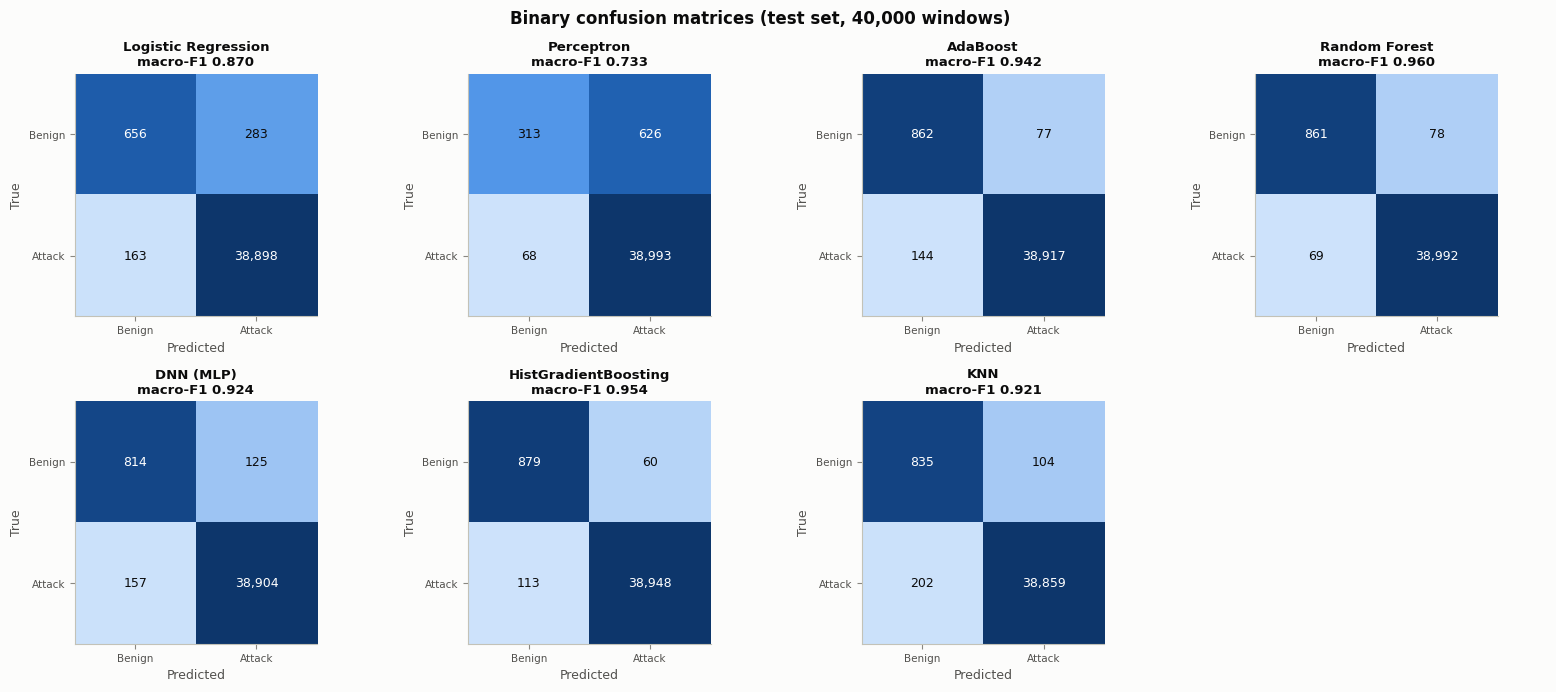

[saved] phase1_outputs\figures\confusion_matrices_multiclass.png


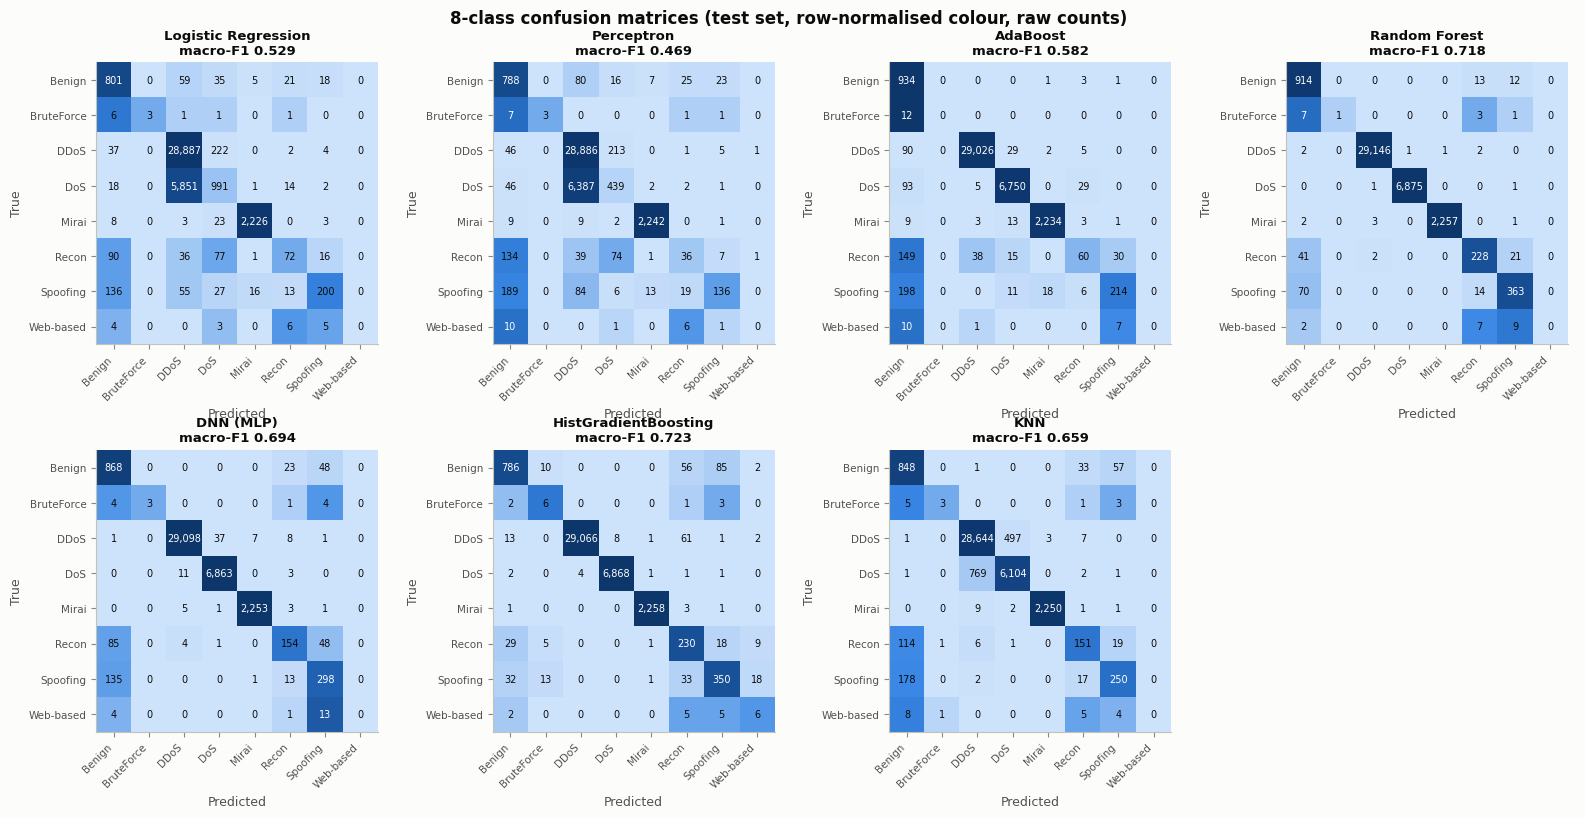

In [23]:
def plot_cm_grid(task, names, fname, title):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8.2 if task == "multiclass" else 7))
    for ax, name in zip(axes.flat, MODEL_ORDER):
        cm = confusion_matrix(y_test if task == "binary" else y_test_mc, PREDS[task][name], labels=range(len(names)))
        norm = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(norm, cmap=BLUES, vmin=0, vmax=1)
        for i in range(len(names)):
            for j in range(len(names)):
                ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=7 if task == "multiclass" else 9,
                        color="#ffffff" if norm[i, j] > 0.55 else INK)
        ax.set_xticks(range(len(names)), names, rotation=45 if task == "multiclass" else 0, ha="right" if task == "multiclass" else "center", fontsize=7.5)
        ax.set_yticks(range(len(names)), names, fontsize=7.5)
        ax.grid(False); ax.set_title(f"{name}\nmacro-F1 {RESULTS[task][name]['macro_f1']:.3f}", fontsize=9.5)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    axes.flat[-1].axis("off")
    fig.suptitle(title, fontsize=12, fontweight="bold", color=INK)
    fig.tight_layout(); savefig(fig, fname); plt.show()

plot_cm_grid("binary", ["Benign", "Attack"], "confusion_matrices_binary", "Binary confusion matrices (test set, 40,000 windows)")
plot_cm_grid("multiclass", CLASS_NAMES, "confusion_matrices_multiclass", "8-class confusion matrices (test set, row-normalised colour, raw counts)")

### 10.3 Feature importance / interpretability
* **Random Forest:** impurity-based importance (fast, built-in; can favour high-cardinality features).
* **HistGradientBoosting:** permutation importance — the drop in macro-F1 when one feature is shuffled — on a stratified 10K sample of the test set (used for interpretation only, never for model choice).

               rf_binary_impurity  rf_multiclass_impurity  hgb_multiclass_permutation
IAT                        0.1265                  0.5000                      0.3887
Min                        0.0159                  0.0687                      0.0565
Tot sum                    0.0254                  0.0457                      0.0146
AVG                        0.0173                  0.0444                      0.0386
flow_duration              0.1199                  0.0438                      0.0641
Header_Length              0.0514                  0.0402                      0.1333
Tot size                   0.0210                  0.0347                      0.0060
Max                        0.0278                  0.0346                      0.0052
Protocol Type              0.0178                  0.0291                      0.0102
urg_count                  0.1596                  0.0236                      0.0661
rst_count                  0.1976                  0.0

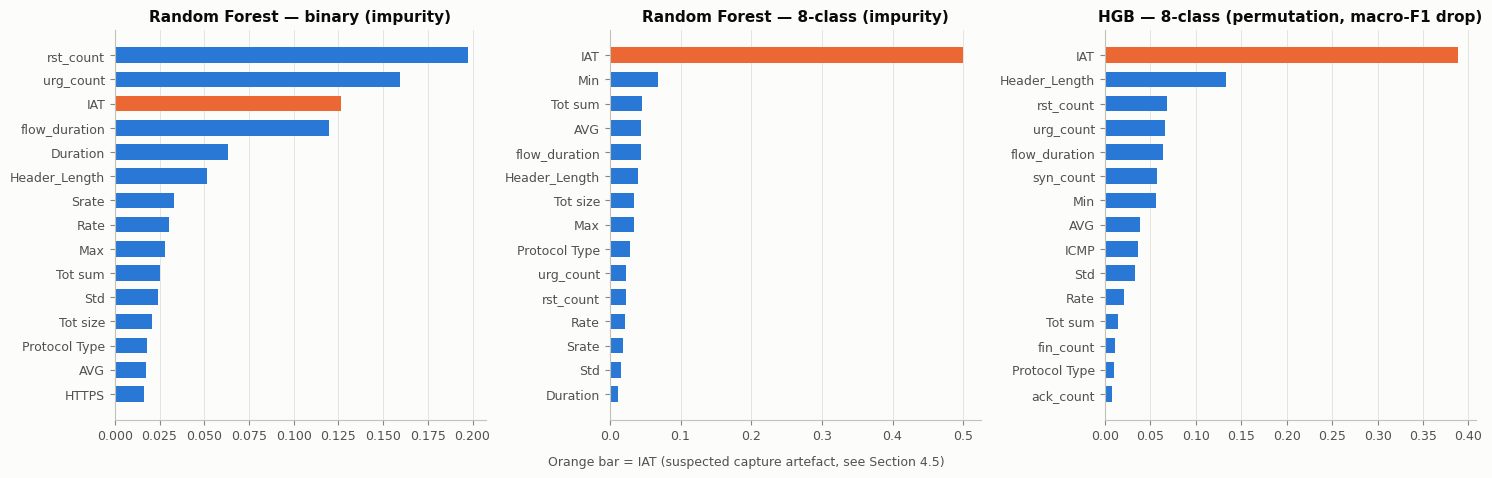

In [24]:
imp_rf_bin = pd.Series(MODELS["binary"]["Random Forest"].feature_importances_, index=FEATURES).sort_values(ascending=False)
imp_rf_mc = pd.Series(MODELS["multiclass"]["Random Forest"].feature_importances_, index=FEATURES).sort_values(ascending=False)
_, sample_idx = train_test_split(np.arange(len(X_test)), test_size=10000, stratify=y_test_mc, random_state=SEED)
pi = permutation_importance(MODELS["multiclass"]["HistGradientBoosting"], X_test.iloc[sample_idx], y_test_mc[sample_idx],
                            scoring="f1_macro", n_repeats=3, random_state=SEED)
imp_hgb_mc = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
imp_tbl = pd.DataFrame({"rf_binary_impurity": imp_rf_bin, "rf_multiclass_impurity": imp_rf_mc,
                        "hgb_multiclass_permutation": imp_hgb_mc}).sort_values("rf_multiclass_impurity", ascending=False)
imp_tbl.to_csv(DIRS["results"] / "feature_importance.csv")
print(imp_tbl.head(15).round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (s, ttl) in zip(axes, ((imp_rf_bin, "Random Forest — binary (impurity)"),
                               (imp_rf_mc, "Random Forest — 8-class (impurity)"),
                               (imp_hgb_mc, "HGB — 8-class (permutation, macro-F1 drop)"))):
    top = s.head(15)[::-1]
    ax.barh(top.index, top.values, color=[SERIES[1] if f == "IAT" else SERIES[0] for f in top.index], height=0.65)
    ax.set_title(ttl); ax.grid(axis="y", visible=False)
fig.text(0.5, -0.02, "Orange bar = IAT (suspected capture artefact, see Section 4.5)", ha="center", color=INK2)
fig.tight_layout(); savefig(fig, "feature_importance"); plt.show()

## 11. Model Comparison
### 11.1 Comparison tables

In [25]:
COLS = ["accuracy", "precision", "recall", "f1", "macro_f1", "weighted_f1", "balanced_accuracy", "mcc",
        "train_time_s", "predict_time_s", "predict_us_per_flow"]
tables = {}
for task in ("binary", "multiclass"):
    order = ["Majority baseline"] + MODEL_ORDER
    extra = ["benign_precision", "benign_recall", "benign_f1"] if task == "binary" else []
    t = pd.DataFrame(RESULTS[task]).T.loc[order, ["source"] + COLS[:4] + extra + COLS[4:]].copy()
    t[COLS + extra] = t[COLS + extra].astype(float)
    tables[task] = t
    t.to_csv(DIRS["results"] / f"model_comparison_{task}.csv")
    label = "precision/recall/F1 = Attack class" if task == "binary" else "precision/recall/F1 = macro average"
    print(f"\n=== {task.upper()} ({label}) — sorted by macro-F1 ===")
    print(t.sort_values("macro_f1", ascending=False).round(4).to_string())


=== BINARY (precision/recall/F1 = Attack class) — sorted by macro-F1 ===
                                         source  accuracy  precision  recall      f1  benign_precision  benign_recall  benign_f1  macro_f1  weighted_f1  balanced_accuracy     mcc  train_time_s  predict_time_s  predict_us_per_flow
Random Forest         existing notebook / paper    0.9963     0.9980  0.9982  0.9981            0.9258         0.9169     0.9213    0.9597       0.9963             0.9576  0.9195        7.3467          0.1411               3.5275
HistGradientBoosting  additional (not in paper)    0.9957     0.9985  0.9971  0.9978            0.8861         0.9361     0.9104    0.9541       0.9957             0.9666  0.9086        7.4578          0.2219               5.5471
AdaBoost                                  paper    0.9945     0.9980  0.9963  0.9972            0.8569         0.9180     0.8864    0.9418       0.9946             0.9572  0.8841       13.4594          0.3516               8.7892
DNN (M

### 11.2 Performance and cost charts

[saved] phase1_outputs\figures\model_comparison_performance.png


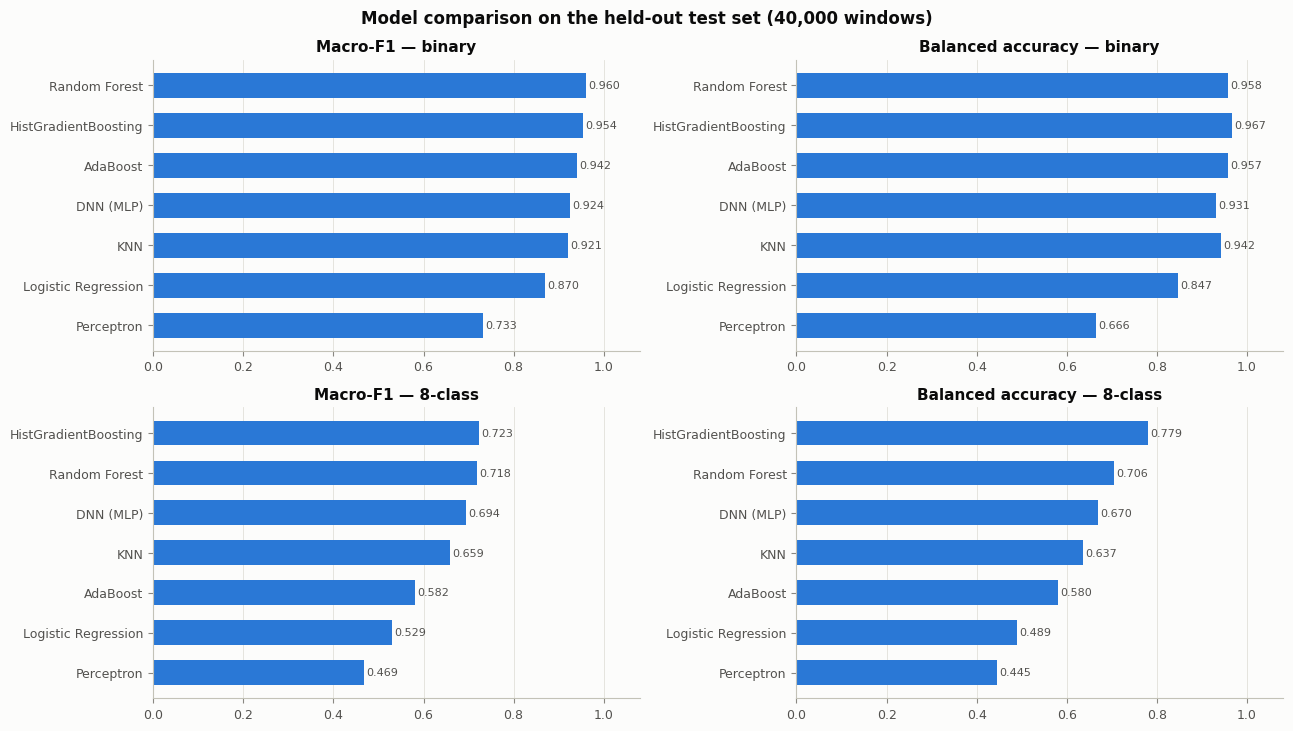

[saved] phase1_outputs\figures\model_comparison_time.png


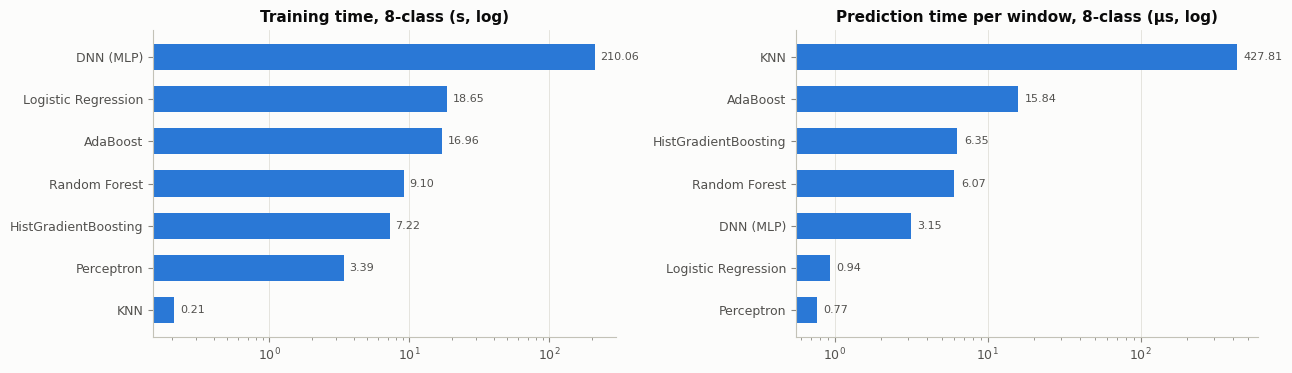

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.4))
for row, task in enumerate(("binary", "multiclass")):
    t = tables[task].loc[MODEL_ORDER].sort_values("macro_f1")
    for col, (metric, ttl) in enumerate((("macro_f1", "Macro-F1"), ("balanced_accuracy", "Balanced accuracy"))):
        ax = axes[row, col]
        ax.barh(t.index, t[metric], color=SERIES[0], height=0.62)
        for yi, v in enumerate(t[metric]):
            ax.text(v + 0.005, yi, f"{v:.3f}", va="center", fontsize=8, color=INK2)
        ax.set_xlim(0, 1.08); ax.grid(axis="y", visible=False)
        ax.set_title(f"{ttl} — {'binary' if task == 'binary' else '8-class'}")
fig.suptitle("Model comparison on the held-out test set (40,000 windows)", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout(); savefig(fig, "model_comparison_performance"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
t = tables["multiclass"].loc[MODEL_ORDER]
for ax, (metric, ttl) in zip(axes, (("train_time_s", "Training time, 8-class (s, log)"),
                                     ("predict_us_per_flow", "Prediction time per window, 8-class (µs, log)"))):
    s = t[metric].sort_values()
    ax.barh(s.index, s.values, color=SERIES[0], height=0.62); ax.set_xscale("log")
    for yi, v in enumerate(s.values):
        ax.text(v * 1.1, yi, f"{v:,.2f}", va="center", fontsize=8, color=INK2)
    ax.set_title(ttl); ax.grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "model_comparison_time"); plt.show()

### 11.3 Uncertainty of the comparison (bootstrap 95% confidence intervals)
Minority classes are tiny, so we resample the test set 200 times (same resamples for every model) and report the 2.5–97.5% range of macro-F1.

In [27]:
rng = np.random.default_rng(SEED)
BOOT = rng.integers(0, len(y_test), size=(200, len(y_test)))
ci_rows = []
for task, yt in (("binary", y_test.to_numpy()), ("multiclass", y_test_mc)):
    for name in MODEL_ORDER:
        p = PREDS[task][name]
        scores = np.array([f1_score(yt[b], p[b], average="macro") for b in BOOT])
        ci_rows.append({"task": task, "model": name, "macro_f1": RESULTS[task][name]["macro_f1"],
                        "ci_low": np.percentile(scores, 2.5), "ci_high": np.percentile(scores, 97.5)})
ci = pd.DataFrame(ci_rows)
ci.to_csv(DIRS["results"] / "bootstrap_macro_f1_ci.csv", index=False)
print(ci.sort_values(["task", "macro_f1"], ascending=[True, False]).round(4).to_string(index=False))

      task                model  macro_f1  ci_low  ci_high
    binary        Random Forest    0.9597  0.9535   0.9656
    binary HistGradientBoosting    0.9541  0.9476   0.9617
    binary             AdaBoost    0.9418  0.9351   0.9490
    binary            DNN (MLP)    0.9244  0.9155   0.9335
    binary                  KNN    0.9206  0.9121   0.9295
    binary  Logistic Regression    0.8703  0.8588   0.8818
    binary           Perceptron    0.7327  0.7157   0.7497
multiclass HistGradientBoosting    0.7234  0.6964   0.7579
multiclass        Random Forest    0.7177  0.6942   0.7563
multiclass            DNN (MLP)    0.6944  0.6424   0.7330
multiclass                  KNN    0.6594  0.6136   0.6933
multiclass             AdaBoost    0.5815  0.5690   0.5930
multiclass  Logistic Regression    0.5290  0.4740   0.5697
multiclass           Perceptron    0.4690  0.4172   0.5059


### 11.4 Sensitivity check 1 — de-duplicated test set
Scores recomputed on the test windows whose exact feature vector does **not** occur in the training file (Section 4.4).

In [28]:
mask = ~TEST_SEEN_IN_TRAIN
dedup_rows = []
for task, yt in (("binary", y_test.to_numpy()), ("multiclass", y_test_mc)):
    for name in MODEL_ORDER:
        p = PREDS[task][name]
        dedup_rows.append({"task": task, "model": name, "macro_f1_full": RESULTS[task][name]["macro_f1"],
                           "macro_f1_dedup": f1_score(yt[mask], p[mask], average="macro"),
                           "accuracy_full": RESULTS[task][name]["accuracy"], "accuracy_dedup": accuracy_score(yt[mask], p[mask])})
dedup = pd.DataFrame(dedup_rows)
dedup.to_csv(DIRS["results"] / "sensitivity_deduplicated_test.csv", index=False)
print(f"De-duplicated test rows: {mask.sum():,} of {len(mask):,}")
print(dedup.round(4).to_string(index=False))

De-duplicated test rows: 38,014 of 40,000
      task                model  macro_f1_full  macro_f1_dedup  accuracy_full  accuracy_dedup
    binary  Logistic Regression         0.8703          0.8701         0.9888          0.9883
    binary           Perceptron         0.7327          0.7325         0.9826          0.9817
    binary             AdaBoost         0.9418          0.9417         0.9945          0.9942
    binary        Random Forest         0.9597          0.9597         0.9963          0.9961
    binary            DNN (MLP)         0.9244          0.9243         0.9930          0.9926
    binary HistGradientBoosting         0.9541          0.9540         0.9957          0.9954
    binary                  KNN         0.9206          0.9205         0.9924          0.9920
multiclass  Logistic Regression         0.5290          0.5284         0.8295          0.8226
multiclass           Perceptron         0.4690          0.4685         0.8132          0.8057
multiclass        

### 11.5 Sensitivity check 2 — IAT ablation
The two strongest model families are retrained **without `IAT`** (same hyper-parameters). A large drop means the model leans on the capture artefact rather than on traffic behaviour.

In [29]:
NO_IAT = [f for f in FEATURES if f != "IAT"]
abl_rows = []
for task, ytr, yte in (("binary", y_train.to_numpy(), y_test.to_numpy()), ("multiclass", y_train_mc, y_test_mc)):
    for name, make in (("Random Forest", lambda: RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
                       ("HistGradientBoosting", lambda: HistGradientBoostingClassifier(max_iter=300, random_state=SEED, **HGB_BEST[task]))):
        m, _ = timed_fit(make(), X_train[NO_IAT], ytr)
        p = m.predict(X_test[NO_IAT])
        abl_rows.append({"task": task, "model": name,
                         "acc_with_IAT": RESULTS[task][name]["accuracy"], "acc_without_IAT": accuracy_score(yte, p),
                         "macroF1_with_IAT": RESULTS[task][name]["macro_f1"], "macroF1_without_IAT": f1_score(yte, p, average="macro")})
ablation = pd.DataFrame(abl_rows)
ablation["macroF1_drop"] = ablation["macroF1_with_IAT"] - ablation["macroF1_without_IAT"]
ablation.to_csv(DIRS["results"] / "sensitivity_iat_ablation.csv", index=False)
print(ablation.round(4).to_string(index=False))

      task                model  acc_with_IAT  acc_without_IAT  macroF1_with_IAT  macroF1_without_IAT  macroF1_drop
    binary        Random Forest        0.9963           0.9932            0.9597               0.9256        0.0341
    binary HistGradientBoosting        0.9957           0.9931            0.9541               0.9273        0.0268
multiclass        Random Forest        0.9946           0.8943            0.7177               0.6296        0.0881
multiclass HistGradientBoosting        0.9892           0.8419            0.7234               0.5947        0.1288


In [30]:
# Save trained models (compressed) so later phases can load them without retraining
for task in ("binary", "multiclass"):
    for name in MODEL_ORDER:
        fname = DIRS["models"] / f"{task}_{name.lower().replace(' ', '_').replace('(', '').replace(')', '')}.joblib"
        joblib.dump(MODELS[task][name], fname, compress=3)
sizes = {p.name: f"{p.stat().st_size / 1e6:.1f} MB" for p in sorted(DIRS["models"].glob("*.joblib"))}
print(json.dumps(sizes, indent=1))

{
 "binary_adaboost.joblib": "0.0 MB",
 "binary_dnn_mlp.joblib": "0.3 MB",
 "binary_histgradientboosting.joblib": "0.3 MB",
 "binary_knn.joblib": "8.9 MB",
 "binary_logistic_regression.joblib": "0.0 MB",
 "binary_perceptron.joblib": "0.0 MB",
 "binary_random_forest.joblib": "2.4 MB",
 "multiclass_adaboost.joblib": "0.0 MB",
 "multiclass_dnn_mlp.joblib": "0.3 MB",
 "multiclass_histgradientboosting.joblib": "0.4 MB",
 "multiclass_knn.joblib": "8.9 MB",
 "multiclass_logistic_regression.joblib": "0.0 MB",
 "multiclass_perceptron.joblib": "0.0 MB",
 "multiclass_random_forest.joblib": "6.3 MB",
 "preprocessing.joblib": "0.0 MB"
}


## 12. Novelty Implementation — Confidence-Gated, Evidence-Grounded Security Recommendation Engine
### 12.1 Is the proposed idea strong enough?
A plain lookup table "predicted class → list of tips" is weak: SIEM/SOAR playbooks already do this, and a lookup table will confidently give the **wrong** advice whenever the classifier is wrong — including for attack types it has never seen (the "closed world" problem of ML-based NIDS [7]). We keep the idea but strengthen it in four ways, each of which is **measured**:

| # | Component | What it adds | How it is measured |
|---|---|---|---|
| 1 | **Selective prediction (confidence gate)** [16], [17] | If the model's top-class probability is below a threshold τ, the engine refuses to give category-specific advice and defers the window to an analyst | Risk–coverage on validation; wrong-advice rate with vs. without the gate |
| 2 | **Open-set safety** | Unknown attack types should be deferred, not mapped to a wrong playbook | Leave-one-class-out experiment |
| 3 | **Per-alert evidence** | Each recommendation lists the traffic features that deviate most from the benign baseline, so the analyst sees *why* | Shown for every alert; IAT excluded from evidence (artefact) |
| 4 | **Protocol-aware, ATT&CK-referenced playbooks** [14], [15] | Flood alerts get protocol-specific steps (SYN, UDP, ICMP, HTTP, GRE) read from the window's own flags; every action cites a MITRE ATT&CK mitigation ID | Mapping unit tests; distribution of protocol contexts |

### 12.2 Literature review
**How existing approaches work.**
* *Explainable IDS.* Wang *et al.* [8] used SHAP [19] to give local and global explanations for an NSL-KDD IDS; El Houda *et al.* [9] combined RuleFit, LIME and SHAP with a DNN for IoT intrusion detection; the survey by Neupane *et al.* [10] notes that most X-IDS work stops at explaining a prediction and calls for explanations tailored to stakeholders and for ways to evaluate them.
* *From explanation to response.* Gyawali *et al.* [11] proposed counterfactual-SHAP explanations to derive "actionable insights" for intrusion response. Islam and Saha [12] (2026 preprint) pair a DNN detector (Benign/DoS/DDoS) with a retrieval-augmented LLM that writes mitigation reports from the top anomalous features. Intrusion-response-system research [13] studies how responses are selected and stresses that responses must be coherent with the detected attack.
* *Knowing when not to answer.* Selective classification [16] thresholds the maximum class probability to guarantee a target error rate on the accepted predictions; the maximum softmax probability is also a standard baseline for detecting misclassified and out-of-distribution inputs [17].

**The gap.** XAI-IDS papers explain but do not recommend; recommendation approaches either generate free text with an LLM (harder to audit, can hallucinate, and not evaluated for wrong-category advice) or assume the classifier is always right. We found no work on CIC-IoT-2023 that (a) refuses category-specific advice when the classifier is uncertain, (b) **quantifies** how often an IDS would give *wrong* defensive advice, including for unseen attack categories, and (c) ties each action to a citable ATT&CK mitigation.

**What is genuinely ours vs. existing.** Existing: the ATT&CK knowledge base and mitigation IDs [14], [15]; the idea of thresholding confidence [16], [17]; feature-based explanations [8]–[10]. **Ours:** the combination into a deterministic, auditable recommendation engine for CIC-IoT-2023 categories; protocol-aware sub-playbooks driven by the window's own features; the threshold chosen on validation data for a target error rate; and the evaluation protocol (correct / wrong / deferred / missed advice rates, comparison against a binary-only baseline and an ungated engine, and a leave-one-class-out open-set test). The novelty is in the system design and its evaluation, not a new learning algorithm.

### 12.3 How the engine works
```
traffic window ──► 8-class model ──► probabilities ──► top class c, confidence p
                                                        │
              p < τ ───────────────────────────────────►│ UNCERTAIN → defer to analyst (triage steps, top-2 candidates)
              c = Benign ──────────────────────────────►│ NO_ACTION → continue monitoring
              c = attack category ─────────────────────►│ CATEGORY_PLAYBOOK(c) + protocol context + evidence
              c not in playbook table (future label) ──►│ UNSUPPORTED_CATEGORY → generic triage, no specific advice
```
Output is a structured record with two clearly separated parts: **`model_prediction`** (what the classifier said) and **`advisory`** (recommendations for a human). It never blocks traffic.

In [31]:
DISCLAIMER = ("Advisory only: these recommendations support a human analyst. They are generated from a model "
              "prediction that can be wrong, and this system does not block, filter, or prevent any traffic.")

def A(action, mid=None, mname=None):
    return {"action": action, "mitigation_id": mid, "mitigation_name": mname}

PLAYBOOKS = {
  "DDoS": {"playbook_id": "PB-DDOS", "title": "Distributed denial-of-service flood (many sources)", "family": "Flood",
           "attck_techniques": [["T1498", "Network Denial of Service"], ["T1498.001", "Direct Network Flood"]],
           "actions": [A("Ask the upstream provider / DDoS-protection service to filter the volumetric traffic before it reaches the IoT network.", "M1037", "Filter Network Traffic"),
                       A("Apply per-source and per-protocol rate limits on the edge router or firewall for the targeted destination.", "M1037", "Filter Network Traffic"),
                       A("If the flooding sources are devices inside the network, move them to a quarantine VLAN.", "M1030", "Network Segmentation"),
                       A("Track packets/s and bytes/s per destination against the normal baseline and keep a packet capture for investigation.")]},
  "DoS": {"playbook_id": "PB-DOS", "title": "Denial-of-service flood (single source)", "family": "Flood",
          "attck_techniques": [["T1499", "Endpoint Denial of Service"], ["T1498.001", "Direct Network Flood"]],
          "actions": [A("Identify the single offending source address and block or rate-limit it at the firewall.", "M1037", "Filter Network Traffic"),
                      A("Enable connection limits and shorter timeouts on the targeted service or device.", "M1037", "Filter Network Traffic"),
                      A("Monitor CPU, memory and connection-table usage of the targeted device to confirm recovery.")]},
  "Mirai": {"playbook_id": "PB-MIRAI", "title": "Mirai-style IoT botnet flood", "family": "Flood",
            "attck_techniques": [["T1498", "Network Denial of Service"], ["T1110", "Brute Force"], ["T1584.005", "Compromise Infrastructure: Botnet"]],
            "actions": [A("Isolate the participating IoT device(s) from the network; reboot and restore firmware before reconnecting (Mirai spreads by guessing default Telnet/SSH passwords [18]).", "M1030", "Network Segmentation"),
                        A("Replace factory-default credentials on all IoT devices with unique strong passwords.", "M1027", "Password Policies"),
                        A("Disable Telnet and other unused remote-administration services on IoT devices.", "M1042", "Disable or Remove Feature or Program"),
                        A("Update device firmware to a version that fixes known weaknesses.", "M1051", "Update Software"),
                        A("Filter the outbound flood at the egress firewall so infected devices cannot attack others.", "M1037", "Filter Network Traffic")]},
  "Recon": {"playbook_id": "PB-RECON", "title": "Reconnaissance / scanning", "family": "Recon",
            "attck_techniques": [["T1595", "Active Scanning"], ["T1046", "Network Service Discovery"]],
            "actions": [A("Raise the scanning source on the watch list and correlate it with later alerts — scans often precede an attack."),
                        A("Close unused ports and disable services the device does not need, to shrink what a scan can find.", "M1042", "Disable or Remove Feature or Program"),
                        A("Keep IoT devices in a separate network segment so a scanner cannot reach everything.", "M1030", "Network Segmentation"),
                        A("Enable IDS/IPS signatures for port-scan, host-discovery and OS-fingerprinting patterns.", "M1031", "Network Intrusion Prevention")]},
  "Spoofing": {"playbook_id": "PB-SPOOF", "title": "ARP / DNS spoofing (adversary-in-the-middle)", "family": "Spoofing",
               "attck_techniques": [["T1557", "Adversary-in-the-Middle"], ["T1557.002", "ARP Cache Poisoning"]],
               "actions": [A("Enable Dynamic ARP Inspection and DHCP snooping on the switches serving the IoT devices.", "M1037", "Filter Network Traffic"),
                           A("Use static ARP entries for critical hosts such as the gateway.", "M1035", "Limit Access to Resource Over Network"),
                           A("Point devices to trusted DNS resolvers that validate DNSSEC, and verify recent DNS answers.", "M1037", "Filter Network Traffic"),
                           A("Prefer encrypted device communication (TLS) so intercepted traffic is not readable.", "M1041", "Encrypt Sensitive Information"),
                           A("Enable IDS/IPS rules for adversary-in-the-middle traffic patterns.", "M1031", "Network Intrusion Prevention")]},
  "Web-based": {"playbook_id": "PB-WEB", "title": "Web application attack (SQLi, command injection, XSS, upload, backdoor)", "family": "Web",
                "attck_techniques": [["T1190", "Exploit Public-Facing Application"]],
                "actions": [A("Put a web application firewall / input validation in front of device web interfaces.", "M1050", "Exploit Protection"),
                            A("Patch the device firmware or web application.", "M1051", "Update Software"),
                            A("Make administrative web interfaces reachable only from the management network.", "M1035", "Limit Access to Resource Over Network"),
                            A("Review web-server logs for injection payloads and run a vulnerability scan of the device.", "M1016", "Vulnerability Scanning")]},
  "BruteForce": {"playbook_id": "PB-BRUTE", "title": "Password brute force / dictionary attack", "family": "BruteForce",
                 "attck_techniques": [["T1110", "Brute Force"], ["T1110.001", "Password Guessing"]],
                 "actions": [A("Enable account lockout or progressive delays after repeated failed logins.", "M1036", "Account Use Policies"),
                             A("Enable multi-factor authentication where the device or service supports it.", "M1032", "Multi-factor Authentication"),
                             A("Replace weak or default passwords; use key-based authentication for SSH.", "M1027", "Password Policies"),
                             A("Monitor the failed-login rate per source and block sources that exceed it.")]},
}
NO_ACTION = {"playbook_id": "PB-NONE", "title": "No attack detected", "family": "Benign", "attck_techniques": [],
             "actions": [A("No defensive action recommended; continue normal monitoring.")]}
TRIAGE = {"playbook_id": "PB-TRIAGE", "title": "Uncertain prediction — analyst review", "family": "Uncertain", "attck_techniques": [],
          "actions": [A("Do not apply category-specific countermeasures yet: the model is not confident about this window."),
                      A("Inspect the source/destination hosts and keep a packet capture of the related traffic."),
                      A("Compare the evidence features and the top-2 candidate categories, then decide manually.")]}
UNSUPPORTED = {"playbook_id": "PB-UNSUPPORTED", "title": "Category without a playbook", "family": "Unsupported", "attck_techniques": [],
               "actions": [A("No category-specific playbook exists for this label; follow the general incident-response procedure."),
                           A("Escalate to an analyst and record the new category so a playbook can be written.")]}

SUBTYPE_ACTIONS = {
  "ICMP flood": [A("Rate-limit or drop ICMP echo requests at the network edge for the targeted hosts.", "M1037", "Filter Network Traffic")],
  "UDP flood": [A("Rate-limit UDP traffic to the target and block UDP ports the device does not use.", "M1037", "Filter Network Traffic")],
  "TCP SYN flood": [A("Enable SYN-flood protection (SYN cookies / SYN proxy) and shorten the half-open connection timeout.", "M1037", "Filter Network Traffic")],
  "TCP flag/connection flood": [A("Use stateful filtering to drop TCP packets that do not belong to an established connection (RST/FIN/PSH-ACK floods).", "M1037", "Filter Network Traffic")],
  "HTTP/application-layer flood": [A("Place a reverse proxy or web application firewall in front of the device web service with request-rate limits and short idle timeouts (also mitigates slow-request attacks such as Slowloris).", "M1037", "Filter Network Traffic")],
  "GRE-encapsulated flood": [A("Drop GRE (IP protocol 47) traffic at the edge if the network does not use GRE tunnels.", "M1037", "Filter Network Traffic")],
  "Unclassified volumetric traffic": [],
}

def protocol_context(x):
    """Read the window's own protocol indicators (window averages in [0,1]) to choose a flood sub-playbook."""
    if x["Protocol Type"] >= 40: return "GRE-encapsulated flood"
    if x["ICMP"] >= 0.5: return "ICMP flood"
    if x["UDP"] >= 0.5: return "UDP flood"
    if x["HTTP"] >= 0.5 or x["HTTPS"] >= 0.5: return "HTTP/application-layer flood"
    if x["TCP"] >= 0.5 and x["syn_flag_number"] >= 0.5: return "TCP SYN flood"
    if x["TCP"] >= 0.5: return "TCP flag/connection flood"
    return "Unclassified volumetric traffic"

mapping_export = {"version": "1.0", "disclaimer": DISCLAIMER, "playbooks": PLAYBOOKS,
                  "special": {"NO_ACTION": NO_ACTION, "UNCERTAIN": TRIAGE, "UNSUPPORTED": UNSUPPORTED},
                  "flood_protocol_subplaybooks": SUBTYPE_ACTIONS,
                  "sources": "MITRE ATT&CK Enterprise (attack.mitre.org), technique and mitigation IDs checked 2026-11-15"}
with open(DIRS["novelty"] / "recommendation_mapping.json", "w", encoding="utf-8") as fh:
    json.dump(mapping_export, fh, indent=2, ensure_ascii=False)
print("Playbooks defined for:", list(PLAYBOOKS))
print("[saved] phase1_outputs/novelty/recommendation_mapping.json")

Playbooks defined for: ['DDoS', 'DoS', 'Mirai', 'Recon', 'Spoofing', 'Web-based', 'BruteForce']
[saved] phase1_outputs/novelty/recommendation_mapping.json


### 12.4 Choosing the probability model and the confidence threshold τ (validation data only)
Candidates: Random Forest and the tuned HistGradientBoosting, both trained on the 80% sub-split and scored on the validation split. We use the **area under the risk–coverage curve (AURC)**: lower means the model's confidence ranks its own mistakes better. Then τ is the smallest value whose accepted predictions have **selective risk ≤ 0.1%** (at most 1 wrong in 1,000 accepted windows) on validation.

Random Forest: validation accuracy 0.9934 | AURC 0.000092
HistGradientBoosting: validation accuracy 0.9925 | AURC 0.000076

Selected probability model: HistGradientBoosting (lowest AURC) | threshold tau = 0.75
                  coverage                     selective_risk              
model HistGradientBoosting Random Forest HistGradientBoosting Random Forest
tau                                                                        
0.30               0.99966       0.99969              0.00725       0.00638
0.35               0.99903       0.99900              0.00691       0.00591
0.40               0.99797       0.99712              0.00633       0.00498
0.45               0.99594       0.99491              0.00546       0.00380
0.50               0.99356       0.99300              0.00412       0.00296
0.55               0.99103       0.99062              0.00331       0.00221
0.60               0.98831       0.98831              0.00247       0.00155
0.65               0.98572    

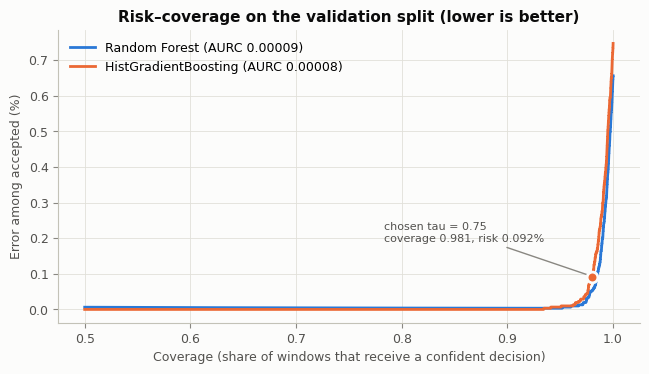

In [32]:
TARGET_RISK = 0.001
rf_val, _ = timed_fit(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_sub, y_sub_mc)
CANDIDATES = {"Random Forest": rf_val, "HistGradientBoosting": HGB_VAL_MODELS["multiclass"]}

def risk_coverage(conf, correct):
    order = np.argsort(-conf, kind="stable")
    errs = np.cumsum(~correct[order]); n = np.arange(1, len(conf) + 1)
    return n / len(conf), errs / n

TAU_GRID = np.round(np.concatenate([np.arange(0.30, 0.95, 0.05), [0.95, 0.97, 0.99]]), 2)
rc, sel_rows = {}, []
for name, m in CANDIDATES.items():
    P = m.predict_proba(X_val); conf, pred = P.max(axis=1), P.argmax(axis=1); correct = pred == y_val_mc
    cov, risk = risk_coverage(conf, correct); rc[name] = (cov, risk)
    for tau in TAU_GRID:
        acc = conf >= tau
        sel_rows.append({"model": name, "tau": tau, "coverage": acc.mean(),
                         "selective_risk": (~correct[acc]).mean() if acc.any() else np.nan})
    print(f"{name}: validation accuracy {correct.mean():.4f} | AURC {risk.mean():.6f}")
sel = pd.DataFrame(sel_rows)
ENGINE_NAME = min(CANDIDATES, key=lambda n: rc[n][1].mean())
cand = sel[(sel.model == ENGINE_NAME) & (sel.selective_risk <= TARGET_RISK)]
TAU = float(cand.tau.min()) if len(cand) else float(sel[sel.model == ENGINE_NAME].sort_values("selective_risk").tau.iloc[0])
ENGINE_MODEL = MODELS["multiclass"][ENGINE_NAME]        # same configuration, refit on the full training set (Section 7/8)
print(f"\nSelected probability model: {ENGINE_NAME} (lowest AURC) | threshold tau = {TAU}")
print(sel.pivot_table(index="tau", columns="model", values=["coverage", "selective_risk"]).round(5).to_string())
sel.to_csv(DIRS["novelty"] / "threshold_selection_validation.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, (name, (cov, risk)) in enumerate(rc.items()):
    start = int(0.5 * len(cov))
    ax.plot(cov[start:], risk[start:] * 100, color=SERIES[i], linewidth=2, label=f"{name} (AURC {risk.mean():.5f})")
r = sel[(sel.model == ENGINE_NAME) & (sel.tau == TAU)].iloc[0]
ax.scatter([r.coverage], [r.selective_risk * 100], s=60, color=SERIES[list(rc).index(ENGINE_NAME)], edgecolor=SURFACE, linewidth=2, zorder=5)
ax.annotate(f"chosen tau = {TAU}\ncoverage {r.coverage:.3f}, risk {r.selective_risk*100:.3f}%", (r.coverage, r.selective_risk * 100),
            xytext=(-150, 25), textcoords="offset points", fontsize=8, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_xlabel("Coverage (share of windows that receive a confident decision)"); ax.set_ylabel("Error among accepted (%)")
ax.set_title("Risk–coverage on the validation split (lower is better)"); ax.legend(loc="upper left")
savefig(fig, "novelty_risk_coverage_validation"); plt.show()

In [33]:
# ---- evidence: deviation from the benign baseline (training data), IAT excluded as an artefact ----
EVIDENCE_FEATURES = [f for f in imp_rf_mc.index if f != "IAT"][:12]
_benign = X_train[y_train.to_numpy() == 0]
BENIGN_MEDIAN, BENIGN_STD = _benign[EVIDENCE_FEATURES].median(), _benign[EVIDENCE_FEATURES].std()

def evidence(x, k=3):
    z = (x[EVIDENCE_FEATURES] - BENIGN_MEDIAN) / (BENIGN_STD + 1e-9)
    top = z.abs().sort_values(ascending=False).head(k).index
    return [{"feature": f, "value": round(float(x[f]), 4), "benign_median": round(float(BENIGN_MEDIAN[f]), 4),
             "deviation_benign_sd": round(float(z[f]), 2), "direction": "higher than benign" if z[f] > 0 else "lower than benign"} for f in top]

def build_advisory(pred_label, confidence, top2, x, tau=TAU, model_name=ENGINE_NAME):
    """Turn ONE model prediction into a structured record: model output and advisory are kept separate."""
    record = {"model_prediction": {"model": model_name, "predicted_class": pred_label, "confidence": round(float(confidence), 4),
                                   "top2_candidates": top2, "threshold_tau": tau},
              "advisory": {}}
    if confidence < tau:
        decision, pb = "UNCERTAIN_REVIEW", TRIAGE
    elif pred_label == "Benign":
        decision, pb = "NO_ACTION", NO_ACTION
    elif pred_label in PLAYBOOKS:
        decision, pb = "CATEGORY_PLAYBOOK", PLAYBOOKS[pred_label]
    else:
        decision, pb = "UNSUPPORTED_CATEGORY", UNSUPPORTED
    adv = {"decision": decision, "playbook_id": pb["playbook_id"], "title": pb["title"],
           "attck_techniques": pb["attck_techniques"], "recommendations": list(pb["actions"]),
           "protocol_context": None, "evidence": evidence(x) if decision != "NO_ACTION" else [], "disclaimer": DISCLAIMER}
    if decision == "CATEGORY_PLAYBOOK" and pb.get("family") == "Flood":
        ctx = protocol_context(x)
        adv["protocol_context"] = ctx
        adv["recommendations"] = adv["recommendations"] + SUBTYPE_ACTIONS[ctx]
    record["advisory"] = adv
    return record

def recommend(x_row, model=None, tau=TAU):
    """End-to-end: one traffic window (pandas Series of the 40 features) -> structured advisory record."""
    model = model or ENGINE_MODEL
    p = model.predict_proba(x_row.to_frame().T[FEATURES])[0]
    order = np.argsort(-p)
    top2 = [[CLASS_NAMES[i], round(float(p[i]), 4)] for i in order[:2]]
    return build_advisory(CLASS_NAMES[order[0]], p[order[0]], top2, x_row, tau=tau)

def show(record):
    mp, ad = record["model_prediction"], record["advisory"]
    print(f"MODEL PREDICTION : {mp['predicted_class']} (confidence {mp['confidence']:.3f}; top-2 {mp['top2_candidates']}; tau {mp['threshold_tau']})")
    print(f"ADVISORY DECISION: {ad['decision']} -> {ad['playbook_id']} | {ad['title']}")
    if ad["attck_techniques"]: print("  ATT&CK techniques:", ", ".join(f"{a} {b}" for a, b in ad["attck_techniques"]))
    if ad["protocol_context"]: print("  Protocol context :", ad["protocol_context"])
    for e in ad["evidence"]:
        print(f"  Evidence: {e['feature']} = {e['value']} ({e['deviation_benign_sd']:+.1f} benign SD, {e['direction']}; benign median {e['benign_median']})")
    for i, r in enumerate(ad["recommendations"], 1):
        print(f"  {i}. {r['action']}" + (f"  [{r['mitigation_id']} {r['mitigation_name']}]" if r["mitigation_id"] else ""))
    print("  " + ad["disclaimer"]); print()

print("Evidence features:", EVIDENCE_FEATURES)
joblib.dump({"engine_model_name": ENGINE_NAME, "tau": TAU, "target_risk": TARGET_RISK, "evidence_features": EVIDENCE_FEATURES,
             "benign_median": BENIGN_MEDIAN, "benign_std": BENIGN_STD, "class_names": CLASS_NAMES},
            DIRS["novelty"] / "engine_config.joblib")
print("[saved] phase1_outputs/novelty/engine_config.joblib")

Evidence features: ['Min', 'Tot sum', 'AVG', 'flow_duration', 'Header_Length', 'Tot size', 'Max', 'Protocol Type', 'urg_count', 'rst_count', 'Rate', 'Srate']
[saved] phase1_outputs/novelty/engine_config.joblib


## 13. Novelty Testing
### 13.1 Unit tests of the recommendation mapping

In [34]:
x0 = X_test.iloc[0]
tests = {}
tests["every attack class has its own playbook"] = all(c in PLAYBOOKS for c in CLASS_NAMES if c != "Benign")
tests["playbooks are category-specific (no two share the same action list)"] = len({json.dumps(p["actions"]) for p in PLAYBOOKS.values()}) == len(PLAYBOOKS)
tests["each attack playbook cites at least one ATT&CK technique and mitigation"] = all(
    p["attck_techniques"] and any(a["mitigation_id"] for a in p["actions"]) for p in PLAYBOOKS.values())
tests["confident Benign -> NO_ACTION"] = build_advisory("Benign", 0.99, [], x0)["advisory"]["decision"] == "NO_ACTION"
tests["low confidence -> UNCERTAIN_REVIEW, even for an attack class"] = build_advisory("DDoS", TAU - 0.01, [], x0)["advisory"]["decision"] == "UNCERTAIN_REVIEW"
tests["low confidence Benign -> UNCERTAIN_REVIEW (possible unseen attack)"] = build_advisory("Benign", TAU - 0.01, [], x0)["advisory"]["decision"] == "UNCERTAIN_REVIEW"
tests["unknown label -> UNSUPPORTED_CATEGORY fallback"] = build_advisory("Ransomware", 0.99, [], x0)["advisory"]["playbook_id"] == "PB-UNSUPPORTED"
tests["model output and advisory are separate fields"] = set(build_advisory("DoS", 0.99, [], x0)) == {"model_prediction", "advisory"}
tests["every advisory carries the 'does not block traffic' disclaimer"] = all(
    "does not block" in build_advisory(c, 0.99, [], x0)["advisory"]["disclaimer"] for c in CLASS_NAMES + ["Unknown"])
tests["flood playbooks receive a protocol context"] = build_advisory("DDoS", 0.99, [], x0)["advisory"]["protocol_context"] is not None
for k, v in tests.items():
    print(("PASS " if v else "FAIL ") + k)
assert all(tests.values()), "A mapping test failed"

PASS every attack class has its own playbook
PASS playbooks are category-specific (no two share the same action list)
PASS each attack playbook cites at least one ATT&CK technique and mitigation
PASS confident Benign -> NO_ACTION
PASS low confidence -> UNCERTAIN_REVIEW, even for an attack class
PASS low confidence Benign -> UNCERTAIN_REVIEW (possible unseen attack)
PASS unknown label -> UNSUPPORTED_CATEGORY fallback
PASS model output and advisory are separate fields
PASS every advisory carries the 'does not block traffic' disclaimer
PASS flood playbooks receive a protocol context


### 13.2 Test-set evaluation: how often is the advice right, wrong, deferred or missing?
Outcome per window (strict = the playbook issued equals the playbook of the true class; *family-relevant* additionally counts DDoS↔DoS↔Mirai mix-ups as relevant because all three share flood countermeasures). Three systems are compared on the same 40K test windows:
* **A — binary detector + generic advice:** the existing binary Random Forest; every detected attack gets the same generic advice (never category-specific).
* **B — category engine without gate (τ = 0):** plain lookup from the predicted class.
* **C — full engine (τ chosen on validation):** our system.

In [35]:
P_test = ENGINE_MODEL.predict_proba(X_test)
pred_lbl = np.array(CLASS_NAMES)[P_test.argmax(axis=1)]
conf_test = P_test.max(axis=1)
true_lbl = test_df["attack_class"].to_numpy()
FAMILY = {c: (PLAYBOOKS[c]["family"] if c in PLAYBOOKS else "Benign") for c in CLASS_NAMES}

def outcomes(true_lbl, pred_lbl, conf, tau):
    out = np.empty(len(true_lbl), dtype=object)
    is_att, deferred = true_lbl != "Benign", conf < tau
    out[deferred] = "Deferred to analyst"
    ok = ~deferred
    out[ok & is_att & (pred_lbl == true_lbl)] = "Correct category playbook"
    out[ok & is_att & (pred_lbl != true_lbl) & (pred_lbl != "Benign")] = "Wrong category playbook"
    out[ok & is_att & (pred_lbl == "Benign")] = "Missed (no action)"
    out[ok & ~is_att & (pred_lbl == "Benign")] = "Correct no action"
    out[ok & ~is_att & (pred_lbl != "Benign")] = "False-alarm playbook"
    return out

def summarise(out, true_lbl, pred_lbl, name):
    att, ben = true_lbl != "Benign", true_lbl == "Benign"
    fam_ok = np.array([FAMILY[p] == FAMILY[t] for p, t in zip(pred_lbl, true_lbl)])
    issued = np.isin(out, ["Correct category playbook", "Wrong category playbook", "False-alarm playbook"])
    return {"system": name,
            "attack: correct specific %": (out[att] == "Correct category playbook").mean() * 100,
            "attack: family-relevant specific %": ((out == "Correct category playbook") | ((out == "Wrong category playbook") & fam_ok))[att].mean() * 100,
            "attack: wrong specific %": (out[att] == "Wrong category playbook").mean() * 100,
            "attack: deferred %": (out[att] == "Deferred to analyst").mean() * 100,
            "attack: missed %": (out[att] == "Missed (no action)").mean() * 100,
            "benign: false-alarm playbook %": (out[ben] == "False-alarm playbook").mean() * 100,
            "benign: deferred %": (out[ben] == "Deferred to analyst").mean() * 100,
            "precision of issued specific playbooks %": (out[issued] == "Correct category playbook").mean() * 100 if issued.any() else np.nan}

# System A: binary detector + generic advice (never category-specific)
bin_pred = PREDS["binary"]["Random Forest"]
att = true_lbl != "Benign"
sysA = {"system": "A: binary RF + generic advice", "attack: correct specific %": 0.0, "attack: family-relevant specific %": 0.0,
        "attack: wrong specific %": 0.0, "attack: deferred %": 0.0,
        "attack: missed %": (bin_pred[att] == 0).mean() * 100,
        "benign: false-alarm playbook %": (bin_pred[~att] == 1).mean() * 100, "benign: deferred %": 0.0,
        "precision of issued specific playbooks %": np.nan,
        "attack: generic advice only %": (bin_pred[att] == 1).mean() * 100}
outB = outcomes(true_lbl, pred_lbl, conf_test, 0.0)
outC = outcomes(true_lbl, pred_lbl, conf_test, TAU)
nov = pd.DataFrame([sysA, summarise(outB, true_lbl, pred_lbl, "B: category engine, no gate"),
                    summarise(outC, true_lbl, pred_lbl, f"C: full engine (tau={TAU})")]).set_index("system")
nov.to_csv(DIRS["novelty"] / "novelty_system_comparison_test.csv")
print(nov.T.round(3).to_string())
wrongB, wrongC = nov.iloc[1]["attack: wrong specific %"], nov.iloc[2]["attack: wrong specific %"]
print(f"\nGate effect on known classes: wrong-category advice {wrongB:.3f}% -> {wrongC:.3f}% of attack windows "
      f"({(1 - wrongC / wrongB) * 100 if wrongB else 0:.0f}% fewer), at the cost of deferring "
      f"{nov.iloc[2]['attack: deferred %']:.2f}% of attack and {nov.iloc[2]['benign: deferred %']:.2f}% of benign windows.")

system                                    A: binary RF + generic advice  B: category engine, no gate  C: full engine (tau=0.75)
attack: correct specific %                                        0.000                       99.291                     98.328
attack: family-relevant specific %                                0.000                       99.327                     98.328
attack: wrong specific %                                          0.000                        0.502                      0.031
attack: deferred %                                                0.000                        0.000                      1.618
attack: missed %                                                  0.177                        0.207                      0.023
benign: false-alarm playbook %                                    8.307                       16.294                      1.065
benign: deferred %                                                0.000                        0.000    

outcome (system C)      n  Correct category playbook  Correct no action  Deferred to analyst  False-alarm playbook  Missed (no action)  Wrong category playbook
true class                                                                                                                                                     
DDoS                29152                      99.26               0.00                 0.73                  0.00                0.00                     0.01
DoS                  6877                      99.21               0.00                 0.79                  0.00                0.00                     0.00
Mirai                2263                      99.65               0.00                 0.31                  0.00                0.00                     0.04
Benign                939                       0.00              57.61                41.32                  1.06                0.00                     0.00
Spoofing              447               

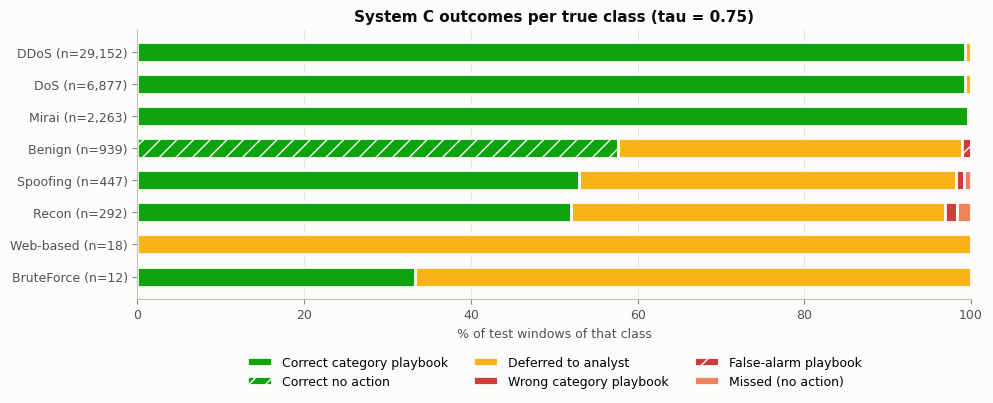

In [36]:
per_cls = pd.crosstab(pd.Series(true_lbl, name="true class"), pd.Series(outC, name="outcome (system C)"), normalize="index") * 100
per_cls.insert(0, "n", pd.Series(true_lbl).value_counts())
per_cls = per_cls.loc[[c for c in dist.index]]
per_cls.to_csv(DIRS["novelty"] / "novelty_outcomes_per_class_test.csv")
print(per_cls.round(2).to_string())

OUTCOME_ORDER = ["Correct category playbook", "Correct no action", "Deferred to analyst", "Wrong category playbook",
                 "False-alarm playbook", "Missed (no action)"]
OUTCOME_COLOR = {"Correct category playbook": STATUS["good"], "Correct no action": STATUS["good"], "Deferred to analyst": STATUS["warning"],
                 "Wrong category playbook": STATUS["critical"], "False-alarm playbook": STATUS["critical"], "Missed (no action)": STATUS["serious"]}
fig, ax = plt.subplots(figsize=(10, 4.2))
cls = per_cls.index.tolist()
left = np.zeros(len(cls))
for o in OUTCOME_ORDER:
    if o not in per_cls.columns: continue
    v = per_cls[o].to_numpy()
    ax.barh(cls, v, left=left, color=OUTCOME_COLOR[o], edgecolor=SURFACE, linewidth=2, height=0.62, label=o,
            hatch="//" if o in ("Correct no action", "False-alarm playbook") else None)
    left += v
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% of test windows of that class"); ax.grid(axis="y", visible=False)
ax.set_yticks(range(len(cls)), [f"{c} (n={per_cls.loc[c, 'n']:,})" for c in cls])
ax.set_title(f"System C outcomes per true class (tau = {TAU})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
fig.tight_layout(); savefig(fig, "novelty_outcomes_per_class"); plt.show()

### 13.3 Open-set test: attack categories the model has never seen
For each minority category we retrain the engine's model **without** that category, then feed it that category's test windows. Without a gate, every confident decision is either *wrong-category advice* or a *silent miss* (predicted Benign). With the gate (same τ, not re-tuned), we count how many are deferred to an analyst instead.

                n test windows  no gate: wrong-category advice %  no gate: silent miss (Benign) %  gate: deferred to analyst %  gate: wrong-category advice %  gate: silent miss %  median confidence
unseen class                                                                                                                                                                                         
Recon                    292.0                             66.78                            33.22                        52.40                          25.34                22.26               0.73
Spoofing                 447.0                             42.06                            57.94                        52.35                           7.61                40.04               0.73
Web-based                 18.0                             83.33                            16.67                        94.44                           5.56                 0.00               0.59
BruteForce

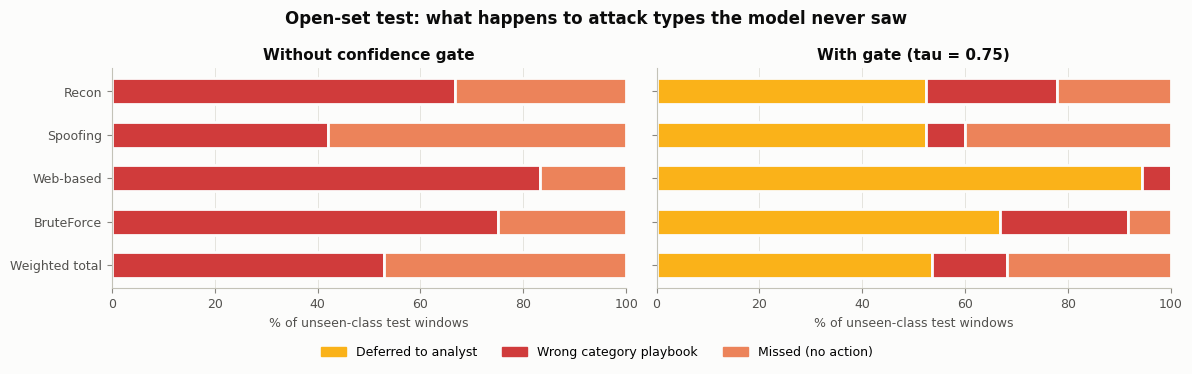

In [37]:
def make_engine_like():
    if ENGINE_NAME == "Random Forest":
        return RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    return HistGradientBoostingClassifier(max_iter=300, random_state=SEED, **HGB_BEST["multiclass"])

open_rows = []
for hold in ["Recon", "Spoofing", "Web-based", "BruteForce"]:
    keep = train_df["attack_class"].to_numpy() != hold
    m = make_engine_like().fit(X_train[keep], train_df["attack_class"].to_numpy()[keep])
    te_mask = true_lbl == hold
    P = m.predict_proba(X_test[te_mask]); pl, cf = m.classes_[P.argmax(axis=1)], P.max(axis=1)
    benign_pred = pl == "Benign"
    gated = cf >= TAU
    open_rows.append({"unseen class": hold, "n test windows": int(te_mask.sum()),
                      "no gate: wrong-category advice %": (~benign_pred).mean() * 100,
                      "no gate: silent miss (Benign) %": benign_pred.mean() * 100,
                      "gate: deferred to analyst %": (~gated).mean() * 100,
                      "gate: wrong-category advice %": (gated & ~benign_pred).mean() * 100,
                      "gate: silent miss %": (gated & benign_pred).mean() * 100,
                      "median confidence": float(np.median(cf))})
open_set = pd.DataFrame(open_rows).set_index("unseen class")
w = open_set["n test windows"]
open_set.loc["Weighted total"] = [w.sum()] + [(open_set[c] * w).sum() / w.sum() for c in open_set.columns[1:]]
open_set.to_csv(DIRS["novelty"] / "novelty_open_set_test.csv")
print(open_set.round(2).to_string())
print("\nNote: Web-based (18) and BruteForce (12) results rest on very few windows.")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
rows_ = open_set.index.tolist()
for ax, (prefix, ttl) in zip(axes, (("no gate", "Without confidence gate"), ("gate", f"With gate (tau = {TAU})"))):
    left = np.zeros(len(rows_))
    parts = [("deferred to analyst %", "Deferred to analyst", STATUS["warning"]),
             ("wrong-category advice %", "Wrong category playbook", STATUS["critical"]),
             ("silent miss (Benign) %" if prefix == "no gate" else "silent miss %", "Missed (no action)", STATUS["serious"])]
    for col, lab, colr in parts:
        key = f"{prefix}: {col}"
        if key not in open_set.columns: continue
        v = open_set[key].to_numpy(); ax.barh(rows_, v, left=left, color=colr, edgecolor=SURFACE, linewidth=2, height=0.6, label=lab); left += v
    ax.set_xlim(0, 100); ax.set_title(ttl); ax.grid(axis="y", visible=False); ax.set_xlabel("% of unseen-class test windows")
axes[0].invert_yaxis()
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (STATUS["warning"], STATUS["critical"], STATUS["serious"])]
fig.legend(handles, ["Deferred to analyst", "Wrong category playbook", "Missed (no action)"], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Open-set test: what happens to attack types the model never saw", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout(); savefig(fig, "novelty_open_set"); plt.show()

### 13.4 Protocol context of flood alerts
The protocol sub-playbook is read from the window's own indicators. The CSVs do not contain the fine-grained attack names, so this cannot be scored against ground truth; we report how the contexts are distributed among confident flood alerts as a sanity check.

In [38]:
flood_mask = (conf_test >= TAU) & np.isin(pred_lbl, ["DDoS", "DoS", "Mirai"])
ctx = X_test[flood_mask].apply(protocol_context, axis=1)
ctx_tbl = pd.crosstab(pd.Series(pred_lbl[flood_mask], name="predicted category"), ctx.rename("protocol context"))
ctx_tbl.to_csv(DIRS["novelty"] / "novelty_protocol_context_counts.csv")
print(ctx_tbl.to_string())

protocol context    GRE-encapsulated flood  HTTP/application-layer flood  ICMP flood  TCP SYN flood  TCP flag/connection flood  UDP flood  Unclassified volumetric traffic
predicted category                                                                                                                                                        
DDoS                                  1033                          2165        4730           5126                       8183       5941                              301
DoS                                    259                           539        1142           1184                       1921       1396                               69
Mirai                                   80                           175         365            369                        682        450                               21


### 13.5 Worked examples from the test set
One correctly detected window per category, one deferred window, and one demonstration of the unsupported-label fallback.

In [39]:
examples = {}
for c in [x for x in dist.index]:
    idx = np.where((true_lbl == c) & (pred_lbl == c) & (conf_test >= TAU))[0]
    if len(idx):
        rec = recommend(X_test.iloc[idx[0]]); rec["test_row"] = int(idx[0]); rec["true_class"] = c
        examples[c] = rec
        print(f"--- Test row {idx[0]} | TRUE CLASS: {c} ---"); show(rec)
    else:
        print(f"--- {c}: no confidently correct window in the test set ---\n")
idx = np.where(conf_test < TAU)[0]
if len(idx):
    rec = recommend(X_test.iloc[idx[0]]); rec["test_row"] = int(idx[0]); rec["true_class"] = true_lbl[idx[0]]
    examples["deferred_example"] = rec
    print(f"--- Test row {idx[0]} | TRUE CLASS: {true_lbl[idx[0]]} (deferred example) ---"); show(rec)
rec = build_advisory("Ransomware", 0.97, [["Ransomware", 0.97]], X_test.iloc[0])
examples["unsupported_label_demo"] = rec
print("--- Synthetic demo: a future model emits a label with no playbook ---"); show(rec)
with open(DIRS["novelty"] / "example_recommendations.json", "w", encoding="utf-8") as fh:
    json.dump(examples, fh, indent=2, ensure_ascii=False, default=str)
print("[saved] phase1_outputs/novelty/example_recommendations.json")

--- Test row 0 | TRUE CLASS: DDoS ---
MODEL PREDICTION : DDoS (confidence 0.945; top-2 [['DDoS', 0.9447], ['Recon', 0.0083]]; tau 0.75)
ADVISORY DECISION: CATEGORY_PLAYBOOK -> PB-DDOS | Distributed denial-of-service flood (many sources)
  ATT&CK techniques: T1498 Network Denial of Service, T1498.001 Direct Network Flood
  Protocol context : HTTP/application-layer flood
  Evidence: Max = 54.0 (-0.5 benign SD, lower than benign; benign median 1137.35)
  Evidence: rst_count = 0.0 (-0.5 benign SD, lower than benign; benign median 635.15)
  Evidence: flow_duration = 0.0 (-0.5 benign SD, lower than benign; benign median 26.5858)
  1. Ask the upstream provider / DDoS-protection service to filter the volumetric traffic before it reaches the IoT network.  [M1037 Filter Network Traffic]
  2. Apply per-source and per-protocol rate limits on the edge router or firewall for the targeted destination.  [M1037 Filter Network Traffic]
  3. If the flooding sources are devices inside the network, move th

## 14. Results and Discussion
*(written after the full run; numbers are taken from the outputs above)*

### 14.1 Binary detection (Benign vs Attack), 40,000 test windows

| Model | Source | Accuracy | Attack-F1 | Benign recall | Macro-F1 [95% CI] | Balanced acc. | MCC | Train (s) |
|---|---|---|---|---|---|---|---|---|
| **Random Forest** | existing / paper | **0.9963** | **0.9981** | 0.917 | **0.960** [0.954, 0.966] | 0.958 | **0.920** | 5.6 |
| HistGradientBoosting | additional | 0.9957 | 0.9978 | **0.936** | 0.954 [0.948, 0.962] | **0.967** | 0.909 | 5.6 |
| AdaBoost | paper | 0.9945 | 0.9972 | 0.918 | 0.942 [0.935, 0.949] | 0.957 | 0.884 | 13.0 |
| DNN (MLP) | paper | 0.9930 | 0.9964 | 0.867 | 0.924 [0.916, 0.934] | 0.931 | 0.849 | 48.0 |
| KNN | additional | 0.9924 | 0.9961 | 0.889 | 0.921 [0.912, 0.930] | 0.942 | 0.842 | 0.4 |
| Logistic Regression | paper | 0.9888 | 0.9943 | 0.699 | 0.870 [0.859, 0.882] | 0.847 | 0.742 | 1.8 |
| Perceptron | paper | 0.9826 | 0.9912 | 0.333 | 0.733 [0.716, 0.750] | 0.666 | 0.517 | 0.6 |
| Majority baseline | reference | 0.9765 | 0.9881 | 0.000 | 0.494 | 0.500 | 0.000 | — |

* Every model beats the majority baseline, but **accuracy and Attack-F1 hide the differences**. The baseline already scores 0.977 / 0.988. Benign recall, macro-F1 and MCC separate the models.
* **Random Forest** is the best overall binary detector (highest macro-F1 and MCC). **HGB** catches more benign traffic correctly (benign recall 0.936 vs 0.917, the best balanced accuracy), so it raises fewer false alarms. Their confidence intervals overlap, so neither is clearly superior.
* The linear models (LR, Perceptron) miss most benign windows. The classes are not linearly separable in the raw feature space.

### 14.2 Eight-class detection (`attack_class`)

| Model | Accuracy | Macro-F1 [95% CI] | Weighted-F1 | Balanced acc. | MCC | Train (s) | Predict (µs/window) |
|---|---|---|---|---|---|---|---|
| **HistGradientBoosting** (class-weighted) | 0.9892 | **0.723** [0.696, 0.758] | 0.990 | **0.779** | 0.975 | 7.4 | 6.3 |
| **Random Forest** | **0.9946** | 0.718 [0.694, 0.756] | **0.994** | 0.706 | **0.988** | 8.3 | 6.3 |
| DNN (MLP) | 0.9884 | 0.694 [0.642, 0.733] | 0.988 | 0.670 | 0.974 | 86.6 | 3.5 |
| KNN | 0.9562 | 0.659 [0.614, 0.693] | 0.955 | 0.637 | 0.899 | 0.2 | 401 |
| AdaBoost | 0.9804 | 0.582 [0.569, 0.593] | 0.979 | 0.580 | 0.956 | 12.0 | 11.4 |
| Logistic Regression | 0.8295 | 0.529 [0.474, 0.570] | 0.782 | 0.490 | 0.576 | 18.3 | 0.7 |
| Perceptron | 0.8132 | 0.469 [0.417, 0.506] | 0.751 | 0.445 | 0.529 | 2.9 | 0.7 |
| Majority baseline | 0.7288 | 0.105 | 0.615 | 0.125 | 0.000 | — | — |

Per-class F1 (test): DDoS, DoS and Mirai ≥ 0.998 for RF and HGB; Benign 0.92 (RF); Spoofing 0.85 (RF); Recon 0.82 (RF); BruteForce ≤ 0.40 for every model (12 windows); **Web-based 0.00 for every model except HGB (0.22)** (18 windows).
* **HGB and RF are statistically tied on macro-F1** (overlapping intervals). They make different trade-offs. Class-weighted HGB recovers more minority-class windows (balanced accuracy 0.779 vs 0.706). RF is more precise and has higher accuracy and MCC.
* As in the paper, all models confuse **Benign, Recon, Spoofing, Web-based and BruteForce** (paper §5.3). These are low-volume, similar-looking traffic types with very few training examples (55 Web-based and 55 BruteForce windows).
* KNN trains instantly but is about 60× slower to predict than the tree ensembles (≈0.4 ms per window), which matters for real-time use.

### 14.3 Reproduction of the paper
| Task | Model | Paper macro-F1 | Ours | Δ |
|---|---|---|---|---|
| binary | Random Forest | 0.965 | 0.960 | −0.006 |
| binary | AdaBoost | 0.956 | 0.942 | −0.015 |
| binary | DNN | 0.940 | 0.924 | −0.016 |
| binary | Logistic Regression | 0.876 | 0.870 | −0.006 |
| binary | Perceptron | 0.811 | 0.733 | −0.078 |
| 8-class | Random Forest | 0.719 | 0.718 | −0.002 |
| 8-class | DNN | 0.697 | 0.694 | −0.003 |
| 8-class | Logistic Regression | 0.539 | 0.529 | −0.010 |
| 8-class | Perceptron | 0.555 | 0.469 | −0.086 |
| 8-class | AdaBoost | 0.369 | 0.582 | +0.213 |

**Verdict:** Random Forest, DNN and Logistic Regression are reproduced closely (within 0.016 macro-F1) despite using 0.4% of the paper's data and 40 instead of 46 features. The binary model ranking is identical to the paper's (RF > AdaBoost > DNN > LR > Perceptron). Two models do **not** match:
* **Perceptron** is lower. It is an unstable linear method, and the result depends heavily on unreported settings.
* **AdaBoost 8-class** is much *higher* than the paper's (0.98 vs 0.35 accuracy). The paper's AdaBoost configuration is unreported and its 0.35 accuracy is below a majority-class guess (0.73), so it was very likely configured differently.

Because the data size, feature set and split differ, this is a **close reproduction of trends and magnitudes, not an exact replication**. The 34-class experiment could not be reproduced: the fine-grained labels are not in the CSVs.

### 14.4 Validity checks
* **Existing RF verified:** re-running the original code gives exactly the recorded accuracy 0.9963 and confusion matrix [[861, 78], [69, 38992]].
* **No test-set tuning:** all hyper-parameters (HGB, KNN) and the novelty threshold τ were chosen on a 20% validation split of the training file. All seven models were scored once on the same untouched 40K test file.
* **Duplicates:** removing the 1,986 test windows that also appear in training changes macro-F1 by at most 0.0006. The overlap does not inflate the results.
* **IAT dependence (major caveat):** without `IAT`, RF 8-class accuracy falls from 0.995 to 0.894 (macro-F1 0.718 → 0.630), and HGB macro-F1 falls 0.723 → 0.595. Binary macro-F1 drops about 0.03. `IAT` is also the top feature for RF (impurity 0.50) and HGB (permutation). Its values cluster by capture session (§4.5), so part of the high 8-class accuracy, especially separating DDoS, DoS and Mirai, likely comes from **capture-session identity rather than traffic behaviour**. Scores on traffic from a different network would probably be lower. This affects the paper's published numbers in the same way, because the paper used the same feature.

### 14.5 Novelty: confidence-gated recommendation engine
**Threshold selection (validation only).** HistGradientBoosting had the lower AURC (its confidence ranks its own mistakes better). Its first threshold meeting the ≤0.1% error target was **τ = 0.75** (validation coverage 98.05%, selective risk 0.092%).

**Known categories, test set (attack windows n = 39,061; benign n = 939):**

| | A: binary RF + generic advice | B: lookup, no gate | **C: full engine (τ = 0.75)** |
|---|---|---|---|
| Attack windows given the **correct category playbook** | 0% (generic only) | 99.29% | 98.33% |
| Attack windows given a **wrong category playbook** | 0% | 0.502% | **0.031%** |
| Attack windows deferred to analyst | — | 0% | 1.62% |
| Attack windows missed (treated as benign) | 0.18% | 0.21% | **0.02%** |
| Benign windows given an attack playbook (false alarm) | 8.31% | 16.29% | **1.07%** |
| Benign windows deferred to analyst | — | 0% | 41.32% |
| Precision of issued category playbooks | — | 99.11% | **99.94%** |

**Unseen categories (leave-one-class-out, 769 test windows of 4 held-out classes):**

| | Without gate | With gate |
|---|---|---|
| Wrong-category advice | 52.9% | **14.6%** |
| Silently treated as benign | 47.1% | 31.9% |
| Deferred to analyst | — | 53.6% |

**Contribution, measured:**
1. **Specificity.** Compared with the binary detector, 98.3% of attack windows receive advice specific to their category instead of a generic message.
2. **Safety on known attacks.** Compared with a plain lookup table, wrong-category advice falls by **94%** (0.502% → 0.031%), benign false-alarm playbooks fall from 16.3% to 1.1%, and missed attacks fall from 0.21% to 0.02%.
3. **Safety on unknown attacks.** Wrong-category advice falls from 52.9% to 14.6%, and over half of unseen-attack windows are routed to a human.
4. **Auditability.** Every action carries an ATT&CK mitigation ID, and every alert carries evidence features and a protocol context (e.g., Mirai GRE floods were correctly given the GRE-specific step, evidenced by `Protocol Type = 47`). Mapping unit tests all pass.

**Costs and limits of the novelty (reported honestly):**
* **Review burden.** 41% of benign windows are deferred: class-weighted HGB is rarely very confident between Benign and the similar minority classes. In absolute terms, about **1,020 of 40,000 windows (2.6%)** go to an analyst. Minority attacks are often deferred too: 45% of Spoofing, 45% of Recon and all 18 Web-based windows.
* **Confidence is not a perfect novelty detector.** 31.9% of unseen-attack windows are still confidently labelled Benign; the gate cannot catch an unknown attack that looks benign to the model. Adding a dedicated out-of-distribution detector (e.g., distance to training data) is future work.
* **Evidence quality.** Evidence is a deviation from the benign baseline, not a causal attribution (SHAP). For flood windows the deviations are small (≈ −0.5 benign SD), because benign traffic itself is very variable.
* **Protocol sub-playbooks** could not be scored against ground truth (fine-grained attack names are absent from the CSVs). Their distribution is reported in §13.4 only as a sanity check.
* **τ was chosen once on validation and not re-tuned on test.** The open-set results therefore show behaviour on genuinely unseen categories, but with small samples for Web-based (18) and BruteForce (12).

## 15. Conclusion

* **Existing work verified.** The original Random Forest reproduces exactly (accuracy 0.9963). Its headline precision/recall/F1 describe the majority Attack class. The informative binary figures are macro-F1 0.960 and benign recall 0.917.
* **Paper reproduced.** All five of the paper's algorithms (LR, Perceptron, AdaBoost, RF, DNN) were run for binary and 8-class detection on the existing 160K/40K split. RF, DNN and LR match the paper within 0.016 macro-F1, and the binary ranking is identical. Perceptron and the paper's 8-class AdaBoost do not match, for the reasons explained in §14.3. The 34-class task cannot be reproduced from these CSVs.
* **Two new algorithms.** HistGradientBoosting and KNN (neither used in the paper) were tuned on validation data only. HGB is the strongest 8-class model (macro-F1 0.723, balanced accuracy 0.779), statistically tied with RF (0.718). RF remains the best binary detector. KNN is competitive in binary detection but slow to predict and weaker on 8 classes.
* **Key caveat.** The `IAT` feature behaves like a capture-session fingerprint. Removing it lowers 8-class accuracy from 0.995 to 0.894, so reported scores (ours and the paper's) are likely optimistic for traffic from new networks.
* **Novelty.** The confidence-gated, evidence-grounded, ATT&CK-referenced engine turns a detection into category-specific advice for 98.3% of attack windows. Compared with a plain lookup it cuts wrong-category advice by 94% on known attacks, and from 52.9% to 14.6% on unseen attack types. The price is that 2.6% of all windows (41% of benign windows) are routed to an analyst. The engine is advisory only and never blocks traffic.
* **Next phase** (out of scope here): serve the saved models and recommendation mapping through the planned backend/frontend.

In [40]:
summary = {"environment": {"python": platform.python_version(), "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
           "data": {"train_rows": len(train_df), "test_rows": len(test_df), "features": len(FEATURES),
                    "test_rows_seen_in_train": int(TEST_SEEN_IN_TRAIN.sum())},
           "existing_rf_verified": now == RECORDED,
           "best_params": {"hgb": HGB_BEST, "knn": KNN_BEST},
           "metrics": {task: {n: {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in r.items()}
                              for n, r in RESULTS[task].items()} for task in RESULTS},
           "novelty": {"engine_model": ENGINE_NAME, "tau": TAU, "target_risk": TARGET_RISK,
                       "system_comparison": nov.round(4).to_dict(orient="index"), "open_set": open_set.round(3).to_dict(orient="index")}}
with open(DIRS["results"] / "phase1_summary.json", "w", encoding="utf-8") as fh:
    json.dump(summary, fh, indent=2, default=str)
print("[saved] phase1_outputs/results/phase1_summary.json\n")
for d in DIRS.values():
    print(f"{d}/"); [print("   ", p.name) for p in sorted(d.iterdir())]

[saved] phase1_outputs/results/phase1_summary.json

phase1_outputs\models/
    binary_adaboost.joblib
    binary_dnn_mlp.joblib
    binary_histgradientboosting.joblib
    binary_knn.joblib
    binary_logistic_regression.joblib
    binary_perceptron.joblib
    binary_random_forest.joblib
    multiclass_adaboost.joblib
    multiclass_dnn_mlp.joblib
    multiclass_histgradientboosting.joblib
    multiclass_knn.joblib
    multiclass_logistic_regression.joblib
    multiclass_perceptron.joblib
    multiclass_random_forest.joblib
    preprocessing.joblib
phase1_outputs\figures/
    confusion_matrices_binary.png
    confusion_matrices_multiclass.png
    eda_class_distribution.png
    eda_feature_correlation.png
    eda_iat_by_class.png
    feature_importance.png
    model_comparison_performance.png
    model_comparison_time.png
    novelty_open_set.png
    novelty_outcomes_per_class.png
    novelty_risk_coverage_validation.png
phase1_outputs\results/
    bootstrap_macro_f1_ci.csv
    class_dis

## 16. References
[1] E. C. P. Neto, S. Dadkhah, R. Ferreira, A. Zohourian, R. Lu, and A. A. Ghorbani, "CICIoT2023: A real-time dataset and benchmark for large-scale attacks in IoT environment," *Sensors*, vol. 23, no. 13, Art. no. 5941, 2023, doi: 10.3390/s23135941.

[2] L. Breiman, "Random forests," *Machine Learning*, vol. 45, no. 1, pp. 5–32, 2001, doi: 10.1023/A:1010933404324.

[3] J. H. Friedman, "Greedy function approximation: A gradient boosting machine," *The Annals of Statistics*, vol. 29, no. 5, pp. 1189–1232, 2001, doi: 10.1214/aos/1013203451.

[4] G. Ke *et al.*, "LightGBM: A highly efficient gradient boosting decision tree," in *Advances in Neural Information Processing Systems 30 (NIPS 2017)*, 2017, pp. 3146–3154.

[5] T. Cover and P. Hart, "Nearest neighbor pattern classification," *IEEE Transactions on Information Theory*, vol. 13, no. 1, pp. 21–27, 1967, doi: 10.1109/TIT.1967.1053964.

[6] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[7] R. Sommer and V. Paxson, "Outside the closed world: On using machine learning for network intrusion detection," in *Proc. IEEE Symposium on Security and Privacy*, 2010, pp. 305–316, doi: 10.1109/SP.2010.25.

[8] M. Wang, K. Zheng, Y. Yang, and X. Wang, "An explainable machine learning framework for intrusion detection systems," *IEEE Access*, vol. 8, pp. 73127–73141, 2020, doi: 10.1109/ACCESS.2020.2988359.

[9] Z. A. El Houda, B. Brik, and L. Khoukhi, "'Why should I trust your IDS?': An explainable deep learning framework for intrusion detection systems in Internet of Things networks," *IEEE Open Journal of the Communications Society*, vol. 3, pp. 1164–1176, 2022, doi: 10.1109/OJCOMS.2022.3188750.

[10] S. Neupane *et al.*, "Explainable intrusion detection systems (X-IDS): A survey of current methods, challenges, and opportunities," *IEEE Access*, vol. 10, pp. 112392–112415, 2022, doi: 10.1109/ACCESS.2022.3216617.

[11] S. Gyawali, J. Huang, and Y. Jiang, "Leveraging explainable AI for actionable insights in IoT intrusion detection," in *Proc. 19th Annual System of Systems Engineering Conference (SoSE)*, 2024, pp. 92–97, doi: 10.1109/SOSE62659.2024.10620966.

[12] M. N. B. Islam and S. Saha, "From detection to response: A deep learning and retrieval-augmented generation framework for network intrusion mitigation," arXiv preprint arXiv:2605.17960, 2026.

[13] Z. Inayat, A. Gani, N. B. Anuar, M. K. Khan, and S. Anwar, "Intrusion response systems: Foundations, design, and challenges," *Journal of Network and Computer Applications*, vol. 62, pp. 53–74, 2016, doi: 10.1016/j.jnca.2015.12.006.

[14] B. E. Strom, A. Applebaum, D. P. Miller, K. C. Nickels, A. G. Pennington, and C. B. Thomas, "MITRE ATT&CK: Design and philosophy," The MITRE Corporation, Tech. Rep. MP 18-03-60, Jul. 2018 (revised Mar. 2020).

[15] The MITRE Corporation, "MITRE ATT&CK Enterprise matrix — techniques T1498, T1499, T1595, T1046, T1557.002, T1190, T1110, T1584.005 and their mitigations." [Online]. Available: https://attack.mitre.org (accessed Nov. 15, 2026).

[16] Y. Geifman and R. El-Yaniv, "Selective classification for deep neural networks," in *Advances in Neural Information Processing Systems 30 (NIPS 2017)*, 2017, pp. 4878–4887.

[17] D. Hendrycks and K. Gimpel, "A baseline for detecting misclassified and out-of-distribution examples in neural networks," in *Proc. International Conference on Learning Representations (ICLR)*, 2017.

[18] M. Antonakakis *et al.*, "Understanding the Mirai botnet," in *Proc. 26th USENIX Security Symposium*, 2017.

[19] S. M. Lundberg and S.-I. Lee, "A unified approach to interpreting model predictions," in *Advances in Neural Information Processing Systems 30 (NIPS 2017)*, 2017, pp. 4765–4774.

[20] lacg030175, "CIC-IoT-2023-neto-full" (configuration `random_3way`), Hugging Face Datasets. [Online]. Available: https://huggingface.co/datasets/lacg030175/CIC-IoT-2023-neto-full (third-party repackaging of [1]).